# Landmark Recognition Using SIFT
### Lab assignment: SIFT keypoints, brute-force matching with Lowe's ratio test, RANSAC localization and evaluation, for a tourism information system

A visitor sends a photo of a famous place. The system compares it with a small database of reference photos and answers three questions: **which landmark is it (or is it none of the ones we know)**, **how sure are we**, and **where is it in the photo**.

**The pipeline in one picture**

```
query photo -> grayscale -> SIFT keypoints + descriptors
            -> match against every reference image (brute force, k=2, ratio test)
            -> rank the landmarks by reliable matches
            -> verify the best candidates geometrically (RANSAC homography)
            -> accept or reject, and draw the landmark region
```

| Lab task | Section |
|---|---|
| 1. Landmark image database | 3 |
| 2. SIFT feature extraction | 4 |
| 3. Query image processing | 5 |
| 4. Feature matching and landmark recognition | 6 (matching) and 8 (decision thresholds) |
| 5. Landmark localization | 7 |
| 6. Performance evaluation | 9 |
| Expected output (the 7 things the application must show) | 10 |

**How to read this notebook.** Every section has the same three parts: **In plain words** (the idea, no maths needed), the code, and **What to look for** (what the output should tell you). The small demos in Sections 4, 6 and 7 are there so that you can *see* each idea instead of only running it. If you can explain every demo in your own words, you can defend the whole lab.

**How the photos are organised (and why it matters)**
- **Database (reference) photos:** 8 per landmark. They are the only photos the system may compare against.
- **Held-out photos:** 4 per landmark, never used as references. They play the role of the visitor's photo.
- **Unknown landmarks:** places that are *not* in the database. Two are used to **choose** the decision thresholds (calibration) and two different ones are used to **test** rejection. Mixing these up would be cheating, so they are kept apart.
- The thresholds are measured on the calibration data only. The test photos are used once, at the end.

**How to run, and how resume works**
- Any runtime works (SIFT runs on the CPU, no GPU is used). Run all cells and allow the Google Drive prompt in Section 2.
- Photos come from **Wikimedia Commons** (free-licence photos). The authors and licences are saved in `credits.csv`. Look at the contact sheets in Section 3 and, if a photo is not the landmark, delete that file from the `landmark_data` folder and run the notebook again from Section 4.
- Everything slow is saved to Drive as it finishes, in `MyDrive/Lab06_SIFT_Landmarks/` (the database, SIFT features, per-query results, figures). If Colab disconnects, reconnect and run all cells again: finished work is loaded and skipped ("already done").
- The run folder name `run_<id>` is a hash of CONFIG. Change a CONFIG value and a fresh run folder is used, so old and new results are never mixed.

## 2. Setup

In [1]:
import os, sys, re, io, time, json, math, random, hashlib, shutil, warnings
from collections import Counter, defaultdict
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Polygon as MplPolygon
import cv2
import requests

assert hasattr(cv2, "SIFT_create"), "This OpenCV build has no SIFT. Run: pip install -U opencv-python"
print("OpenCV", cv2.__version__, "| numpy", np.__version__, "| pandas", pd.__version__)

SEED = 42
random.seed(SEED); np.random.seed(SEED)

CONFIG = {
    "seed": SEED,
    # ---- the landmarks: Wikimedia Commons category names to try (in order), then a file-name search ----
    "landmarks": {                                   # in the database (known)
        "Big Ben": ["Elizabeth Tower", "Big Ben"],
        "Sydney Opera House": ["Sydney Opera House"],
        "Leaning Tower of Pisa": ["Leaning Tower of Pisa"],
        "Hagia Sophia": ["Hagia Sophia"],
        "Burj Khalifa": ["Burj Khalifa"],
        "Angkor Wat": ["Angkor Wat"],
        "Petra Treasury": ["Al Khazneh", "Al-Khazneh", "Treasury (Petra)"],
    },
    "unknown_calibration": {                         # NOT in the database: used to choose thresholds
        "Golden Gate Bridge": ["Golden Gate Bridge"],
        "Brandenburg Gate": ["Brandenburg Gate"],
    },
    "unknown_test": {                                # NOT in the database: used only for the final test
        "Great Pyramid of Giza": ["Great Pyramid of Giza"],
        "Eiffel Tower": ["Eiffel Tower"],
    },
    "images_per_landmark": 12,                       # 8 go to the database, the rest are held out as queries
    "database_per_landmark": 8,
    "images_per_unknown": 6,
    "download": {
        "user_agent": "Lab06-SIFT-Landmarks/1.0 (university lab project; https://github.com/AdeelAsghar11/ComputerVision-AI-7)",
        "thumb_width": 1280, "save_max_side": 1024,
        "max_candidates": 400, "max_subcategories": 8, "min_candidates": 25, "max_info": 150,
        "min_width": 1000, "min_height": 700, "aspect_range": [0.55, 1.9],
        "max_per_artist": 2, "dup_hamming": 5, "pause": 0.25,
    },
    # ---- SIFT, matching, geometry ----
    "sift": {"nfeatures": 1500, "nOctaveLayers": 3, "contrastThreshold": 0.04, "edgeThreshold": 10, "sigma": 1.6, "max_side": 800},
    "ratio": 0.75,                                   # Lowe's ratio test
    "ransac": {"reproj_threshold": 5.0, "max_iters": 2000, "confidence": 0.995, "min_matches": 8},
    "verify_top_landmarks": 3,                       # how many landmark candidates get the geometric check
    "polygon": {"min_area_frac": 0.005, "max_area_frac": 25.0, "max_side_ratio": 20.0, "min_angle": 20.0, "max_angle": 160.0},
    # ---- choosing the decision thresholds (calibration) ----
    "calibration": {"t_good_grid": [8, 10, 12, 15, 20, 25, 30], "t_inliers_grid": [6, 8, 10, 12, 15, 20, 25, 30],
                    "margin_grid": [1.0, 1.25, 1.5, 2.0], "allowed_unknown_accept": [0.0, 0.1, 0.25]},
    # ---- Task 6 test conditions and sweeps ----
    "conditions": {"rotation_deg": 45, "scale": 0.5, "brightness": 0.4},
    "sweeps": {"rotation": [0, 15, 30, 45, 60, 90, 135, 180], "scale": [0.25, 0.35, 0.5, 0.75, 1.0, 1.5],
               "brightness": [0.15, 0.3, 0.5, 0.75, 1.0, 1.5]},
    # ---- persistence (not part of the run id) ----
    "save_to_drive": True,
    "drive_folder": "Lab06_SIFT_Landmarks",
    "rebuild_database": False,
}
CONFIG

OpenCV 4.14.0 | numpy 2.1.3 | pandas 2.2.3


{'seed': 42,
 'landmarks': {'Big Ben': ['Elizabeth Tower', 'Big Ben'],
  'Sydney Opera House': ['Sydney Opera House'],
  'Leaning Tower of Pisa': ['Leaning Tower of Pisa'],
  'Hagia Sophia': ['Hagia Sophia'],
  'Burj Khalifa': ['Burj Khalifa'],
  'Angkor Wat': ['Angkor Wat'],
  'Petra Treasury': ['Al Khazneh', 'Al-Khazneh', 'Treasury (Petra)']},
 'unknown_calibration': {'Golden Gate Bridge': ['Golden Gate Bridge'],
  'Brandenburg Gate': ['Brandenburg Gate']},
 'unknown_test': {'Great Pyramid of Giza': ['Great Pyramid of Giza'],
  'Eiffel Tower': ['Eiffel Tower']},
 'images_per_landmark': 12,
 'database_per_landmark': 8,
 'images_per_unknown': 6,
 'download': {'user_agent': 'Lab06-SIFT-Landmarks/1.0 (university lab project; https://github.com/AdeelAsghar11/ComputerVision-AI-7)',
  'thumb_width': 1280,
  'save_max_side': 1024,
  'max_candidates': 400,
  'max_subcategories': 8,
  'min_candidates': 25,
  'max_info': 150,
  'min_width': 1000,
  'min_height': 700,
  'aspect_range': [0.55, 1.

In [2]:
# ---- run id, Google Drive, folders ----
def _sig_dict(c):
    d = {k: v for k, v in c.items() if k not in {"save_to_drive", "drive_folder", "rebuild_database"}}
    d["download"] = {k: v for k, v in c["download"].items() if k not in ("user_agent", "pause")}
    return d

RUN_SIG = hashlib.md5(json.dumps(_sig_dict(CONFIG), sort_keys=True).encode()).hexdigest()[:8]
_db_part = {k: CONFIG[k] for k in ("seed", "landmarks", "unknown_calibration", "unknown_test", "images_per_landmark",
                                   "database_per_landmark", "images_per_unknown")}
_db_part["download"] = _sig_dict(CONFIG)["download"]
DB_SIG = hashlib.md5(json.dumps(_db_part, sort_keys=True).encode()).hexdigest()[:8]

BASE_DIR = "/content/lab06_local_ckpt"            # used only if Drive cannot be mounted
DRIVE_OK = False
if CONFIG["save_to_drive"]:
    try:
        from google.colab import drive
        drive.mount("/content/drive")
        BASE_DIR = os.path.join("/content/drive/MyDrive", CONFIG["drive_folder"])
        DRIVE_OK = True
    except Exception as e:
        print("Google Drive is not available here:", repr(e))
        print("Files go to", BASE_DIR, "(LOCAL ONLY: lost if the runtime resets)")

CKPT_DIR = os.path.join(BASE_DIR, f"run_{RUN_SIG}")
FIG_DIR = os.path.join(CKPT_DIR, "figures")
DRIVE_DATA = os.path.join(BASE_DIR, "landmark_data")     # the photo database lives here between sessions
LOCAL_DATA = "/content/lab06_data"                       # working copy (fast to read)
RESULTS_DIR = "/content/lab06_results"
for d in (CKPT_DIR, FIG_DIR, DRIVE_DATA, RESULTS_DIR):
    os.makedirs(d, exist_ok=True)
print("Run id:", RUN_SIG, "| database id:", DB_SIG)
print("Checkpoint folder:", CKPT_DIR, "(Google Drive)" if DRIVE_OK else "(local)")


def _json_default(o):
    if isinstance(o, np.integer): return int(o)
    if isinstance(o, np.floating): return float(o)
    if isinstance(o, np.ndarray): return o.tolist()
    return str(o)


def _atomic_write(path, text):
    tmp = path + ".tmp"
    with open(tmp, "w") as f:
        f.write(text)
    os.replace(tmp, path)          # a disconnect can never leave a half-written file behind


class JsonStore:
    """Small results saved as JSON after every change (best settings, per-query results)."""
    def __init__(self, filename):
        self.path = os.path.join(CKPT_DIR, filename)
        self.data = {}
        if os.path.exists(self.path):
            try:
                self.data = json.load(open(self.path))
                print(f"  [{filename}] loaded {len(self.data)} saved entries")
            except Exception:
                self.data = {}
    def has(self, key): return key in self.data
    def get(self, key, default=None): return self.data.get(key, default)
    def set(self, key, value):
        self.data[key] = value
        _atomic_write(self.path, json.dumps(self.data, default=_json_default))
    def put(self, key, value):
        self.data[key] = value                      # in memory only; call flush() to write
    def flush(self):
        _atomic_write(self.path, json.dumps(self.data, default=_json_default))
    def reset(self):
        self.data = {}
        if os.path.exists(self.path): os.remove(self.path)


EXTRAS = JsonStore("extras.json")          # settings and summaries
QRES = JsonStore("query_results.json")     # one entry per query photo that has been analysed


def _clean_axis(ax):
    '''Hide ticks/spines but keep title/xlabel/ylabel visible (unlike ax.axis("off"),
    which hides the labels too).'''
    ax.set_xticks([]); ax.set_yticks([])
    for spine in ax.spines.values():
        spine.set_visible(False)


def save_fig(name, fig=None):
    fig = fig or plt.gcf()
    path = os.path.join(RESULTS_DIR, name + ".png")
    fig.savefig(path, dpi=130, bbox_inches="tight")
    try:
        shutil.copy(path, os.path.join(FIG_DIR, name + ".png"))
    except Exception as e:
        print("(figure could not be copied to the checkpoint folder)", e)


def show_bgr(ax, bgr, title=None, fontsize=9):
    ax.imshow(cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB))
    if title: ax.set_title(title, fontsize=fontsize)
    _clean_axis(ax)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Run id: 9fb91e8d | database id: 7c8207c1
Checkpoint folder: /content/drive/MyDrive/Lab06_SIFT_Landmarks/run_9fb91e8d (Google Drive)
  [extras.json] loaded 3 saved entries
  [query_results.json] loaded 96 saved entries


## 3. Task 1: Landmark image database

**In plain words.** The system can only recognise what it has seen before, so first we need reference photos: several photos of each landmark, taken from different sides and distances. Here they are downloaded from Wikimedia Commons, one folder per landmark, exactly as the brief asks:

```
landmark_data/
  database/<landmark>/...            8 reference photos per landmark
  queries/known/<landmark>/...       4 held-out photos per landmark (the "visitor" photos)
  queries/unknown_calibration/...    places NOT in the database, used to choose thresholds
  queries/unknown_test/...           places NOT in the database, used for the final test
  credits.csv                        author and licence of every photo
```

**How the photos are picked.** A Commons category holds hundreds of files of all kinds (drawings, maps, interiors, night shots). The downloader keeps only JPEG photos that are large enough, skips titles that look like maps, models, interiors and so on, allows at most 2 photos per author (so one photographer's burst of near-identical shots cannot fill the database), and drops near-duplicates with a tiny image fingerprint (a "difference hash").

**What to look for.** The contact sheets must show the right landmark in every cell. A wrong photo (an interior, a replica, another building) would only confuse the experiment, so delete it and re-run.

In [3]:
EXCLUDE_RE = re.compile(
    r"\b(interior|interiors|inside|indoor|detail|details|close[- ]?up|model|replica|miniature|lego|map|plan|poster|logo|"
    r"diagram|drawing|sketch|painting|engraving|postcard|stamp|coin|icon|flag|sign|plaque|panorama|aerial|drone|"
    r"satellite|night|evening|dusk|fireworks?|christmas|selfie|crowd|ceremony|wedding|exhibition|restaurant|train|bus)\b", re.I)


def slug(s):
    return re.sub(r"[^a-z0-9]+", "_", s.lower()).strip("_")


def strip_html(s):
    return re.sub(r"\s+", " ", re.sub(r"<[^>]+>", " ", s or "")).strip()


def dhash(bgr, size=8):
    '''64-bit "difference hash": brightness comparisons between neighbouring pixels of an 9x8 thumbnail.'''
    g = cv2.cvtColor(bgr, cv2.COLOR_BGR2GRAY)
    r = cv2.resize(g, (size + 1, size), interpolation=cv2.INTER_AREA)
    bits = (r[:, 1:] > r[:, :-1]).flatten()
    return int("".join("1" if b else "0" for b in bits), 2)


def hamming(a, b):
    return bin(a ^ b).count("1")


def make_session():
    s = requests.Session()
    s.headers.update({"User-Agent": CONFIG["download"]["user_agent"]})
    return s


class CommonsClient:
    """Tiny client for the Wikimedia Commons API (category listing, image information, search, download)."""
    API = "https://commons.wikimedia.org/w/api.php"

    def __init__(self):
        self.s = make_session()
        self.pause = CONFIG["download"]["pause"]

    def _call(self, params, post=False):
        base = {"action": "query", "format": "json", "formatversion": "2"}
        base.update(params)
        for attempt in range(4):
            r = self.s.post(self.API, data=base, timeout=30) if post else self.s.get(self.API, params=base, timeout=30)
            if r.status_code == 200:
                time.sleep(self.pause)
                return r.json()
            if r.status_code in (429, 503):
                time.sleep(3 * (attempt + 1)); continue
            r.raise_for_status()
        raise RuntimeError("Wikimedia Commons did not answer (too many requests?). Wait a minute and run the cell again.")

    def members(self, category, kind="file", limit=500):
        out, cont = [], {}
        while len(out) < limit:
            p = {"list": "categorymembers", "cmtitle": "Category:" + category, "cmtype": kind, "cmlimit": "500"}
            p.update(cont)
            data = self._call(p)
            out += [m["title"] for m in data.get("query", {}).get("categorymembers", [])]
            cont = data.get("continue", {})
            if not cont:
                break
        return out[:limit]

    def search_files(self, text, limit=200):
        out, offset = [], 0
        while len(out) < limit:
            data = self._call({"list": "search", "srsearch": text + " filetype:bitmap", "srnamespace": "6",
                               "srlimit": "50", "sroffset": str(offset)})
            hits = data.get("query", {}).get("search", [])
            if not hits:
                break
            out += [h["title"] for h in hits]
            offset += 50
            if "continue" not in data:
                break
        return out[:limit]

    def imageinfo(self, titles):
        out = {}
        for i in range(0, len(titles), 40):
            chunk = titles[i:i + 40]
            data = self._call({"prop": "imageinfo", "titles": "|".join(chunk), "iiprop": "url|size|mime|extmetadata",
                               "iiurlwidth": str(CONFIG["download"]["thumb_width"]),
                               "iiextmetadatafilter": "Artist|LicenseShortName"}, post=True)
            for pg in data.get("query", {}).get("pages", []):
                ii = pg.get("imageinfo")
                if not ii:
                    continue
                ii = ii[0]
                md = ii.get("extmetadata", {}) or {}
                out[pg["title"]] = dict(url=ii.get("thumburl") or ii.get("url"), width=ii.get("width") or 0,
                                        height=ii.get("height") or 0, mime=ii.get("mime", ""),
                                        page=ii.get("descriptionurl", ""),
                                        artist=strip_html((md.get("Artist") or {}).get("value", "")),
                                        license=(md.get("LicenseShortName") or {}).get("value", ""))
        return out

    def fetch(self, url):
        for attempt in range(4):
            r = self.s.get(url, timeout=60)
            if r.status_code == 200:
                time.sleep(self.pause)
                return r.content
            if r.status_code in (429, 503):
                time.sleep(4 * (attempt + 1)); continue
            r.raise_for_status()
        raise RuntimeError("download failed: " + url)


def collect_titles(client, categories, cap, rng):
    '''File titles for one landmark: the first category that gives enough files, otherwise a text search.'''
    dl = CONFIG["download"]
    for cat in categories:
        titles = list(client.members(cat, "file", limit=cap))
        subs = [t.split(":", 1)[1] for t in client.members(cat, "subcat", limit=200)]
        subs = [s for s in subs if not EXCLUDE_RE.search(s)]
        rng.shuffle(subs)
        used = subs[:dl["max_subcategories"]]
        for sc in used:
            if len(titles) >= cap:
                break
            titles += client.members(sc, "file", limit=max(cap // 2, 50))
        titles = [t for t in dict.fromkeys(titles) if t.lower().endswith((".jpg", ".jpeg"))]
        if len(titles) >= dl["min_candidates"]:
            return titles, f"Category:{cat} (+{len(used)} subcategories)"
    q = categories[0]
    titles = [t for t in client.search_files(q, limit=cap) if t.lower().endswith((".jpg", ".jpeg"))]
    return titles, f"file-name search: {q}"


def acquire(client, landmark, categories, n_needed, rng, seen_hashes):
    dl = CONFIG["download"]
    titles, source = collect_titles(client, categories, dl["max_candidates"], rng)
    titles = [t for t in titles if not EXCLUDE_RE.search(t)]
    rng.shuffle(titles)
    titles = titles[:dl["max_info"]]
    info = client.imageinfo(titles)
    cands = []
    for t in titles:
        d = info.get(t)
        if not d or d["mime"] != "image/jpeg" or d["width"] < dl["min_width"] or d["height"] < dl["min_height"]:
            continue
        ar = d["width"] / max(d["height"], 1)
        if dl["aspect_range"][0] <= ar <= dl["aspect_range"][1]:
            cands.append((t, d))
    chosen, per_artist = [], Counter()
    for strict in (True, False):                   # second pass relaxes the "2 per author" rule if we are short
        for t, d in cands:
            if len(chosen) >= n_needed:
                break
            if any(c["title"] == t for c in chosen):
                continue
            a = (d["artist"] or "unknown").lower()[:60]
            if strict and per_artist[a] >= dl["max_per_artist"]:
                continue
            try:
                raw = client.fetch(d["url"])
                img = cv2.imdecode(np.frombuffer(raw, np.uint8), cv2.IMREAD_COLOR)
            except Exception as e:
                print(f"   skipped {t[:50]}: {e}"); continue
            if img is None:
                continue
            h = dhash(img)
            if any(hamming(h, h2) <= dl["dup_hamming"] for h2 in seen_hashes):
                continue
            seen_hashes.append(h); per_artist[a] += 1
            chosen.append(dict(title=t, img=img, **d))
    return chosen, source, len(titles), len(cands)


def build_database():
    dl = CONFIG["download"]
    client = CommonsClient()
    if os.path.exists(LOCAL_DATA):
        shutil.rmtree(LOCAL_DATA)
    credits, report, seen = [], [], []

    def save_group(role, folder, landmark, items, k_start=1):
        os.makedirs(os.path.join(LOCAL_DATA, folder, landmark), exist_ok=True)
        for k, it in enumerate(items, start=k_start):
            img = it["img"]
            h, w = img.shape[:2]
            s = max(h, w)
            if s > dl["save_max_side"]:
                img = cv2.resize(img, (round(w * dl["save_max_side"] / s), round(h * dl["save_max_side"] / s)), interpolation=cv2.INTER_AREA)
            fname = f"{slug(landmark)}_{k:02d}.jpg"
            cv2.imwrite(os.path.join(LOCAL_DATA, folder, landmark, fname), img, [cv2.IMWRITE_JPEG_QUALITY, 90])
            credits.append(dict(role=role, landmark=landmark, file=f"{folder}/{landmark}/{fname}", commons_title=it["title"],
                                page=it["page"], author=it["artist"], license=it["license"],
                                original_size=f"{it['width']}x{it['height']}"))

    jobs = [("known", lm, cats, CONFIG["images_per_landmark"]) for lm, cats in CONFIG["landmarks"].items()]
    jobs += [("unknown_calibration", lm, cats, CONFIG["images_per_unknown"]) for lm, cats in CONFIG["unknown_calibration"].items()]
    jobs += [("unknown_test", lm, cats, CONFIG["images_per_unknown"]) for lm, cats in CONFIG["unknown_test"].items()]
    for role, lm, cats, n in jobs:
        print(f"[{role}] {lm} ...", flush=True)
        rng = random.Random(CONFIG["seed"] + sum(map(ord, lm)))
        chosen, source, n_titles, n_cands = acquire(client, lm, cats, n, rng, seen)
        report.append(dict(role=role, landmark=lm, source=source, titles_found=n_titles, passed_filters=n_cands, downloaded=len(chosen)))
        if role == "known":
            if len(chosen) < 5:
                print(f"   WARNING: only {len(chosen)} usable photos for {lm}; it is skipped.")
                continue
            rng.shuffle(chosen)
            n_db = min(CONFIG["database_per_landmark"], len(chosen) - 1)
            save_group("database", "database", lm, chosen[:n_db])
            save_group("held_out", "queries/known", lm, chosen[n_db:], k_start=n_db + 1)
        else:
            if len(chosen) < 2:
                print(f"   WARNING: only {len(chosen)} usable photos for {lm}.")
            save_group(role, "queries/" + role, lm, chosen)
    pd.DataFrame(credits).to_csv(os.path.join(LOCAL_DATA, "credits.csv"), index=False)
    open(os.path.join(LOCAL_DATA, "db_signature.txt"), "w").write(DB_SIG)
    print("\nDownload report")
    print(pd.DataFrame(report).to_string(index=False))
    shutil.copytree(LOCAL_DATA, DRIVE_DATA, dirs_exist_ok=True)       # keep a copy on Drive
    print("\nDatabase saved to", DRIVE_DATA)


def db_ready(path):
    f = os.path.join(path, "db_signature.txt")
    return os.path.exists(f) and open(f).read().strip() == DB_SIG


# ---- network self-test, then build or load the database ----
if db_ready(LOCAL_DATA) and not CONFIG["rebuild_database"]:
    print("Using the database already in", LOCAL_DATA)
elif db_ready(DRIVE_DATA) and not CONFIG["rebuild_database"]:
    shutil.copytree(DRIVE_DATA, LOCAL_DATA, dirs_exist_ok=True)
    print("Database copied from Drive:", DRIVE_DATA)
else:
    try:
        probe = CommonsClient().members(list(CONFIG["landmarks"].values())[0][0], "file", limit=5)
        print("Wikimedia Commons answered. Example files:", probe[:2])
    except Exception as e:
        raise RuntimeError("Cannot reach Wikimedia Commons from this runtime: " + repr(e) +
                           "\nFallback: put your own photos in the folder layout shown above inside " + LOCAL_DATA +
                           ", write the text " + DB_SIG + " into db_signature.txt there, and run this cell again.")
    build_database()

Using the database already in /content/lab06_data


108 photos, 7 known landmarks: ['Angkor Wat', 'Big Ben', 'Burj Khalifa', 'Hagia Sophia', 'Leaning Tower of Pisa', 'Petra Treasury', 'Sydney Opera House']
role                   ref  heldout  unk_cal  unk_test
landmark                                              
Angkor Wat               8        4        0         0
Big Ben                  8        4        0         0
Brandenburg Gate         0        0        6         0
Burj Khalifa             8        4        0         0
Eiffel Tower             0        0        0         6
Golden Gate Bridge       0        0        6         0
Great Pyramid of Giza    0        0        0         6
Hagia Sophia             8        4        0         0
Leaning Tower of Pisa    8        4        0         0
Petra Treasury           8        4        0         0
Sydney Opera House       8        4        0         0


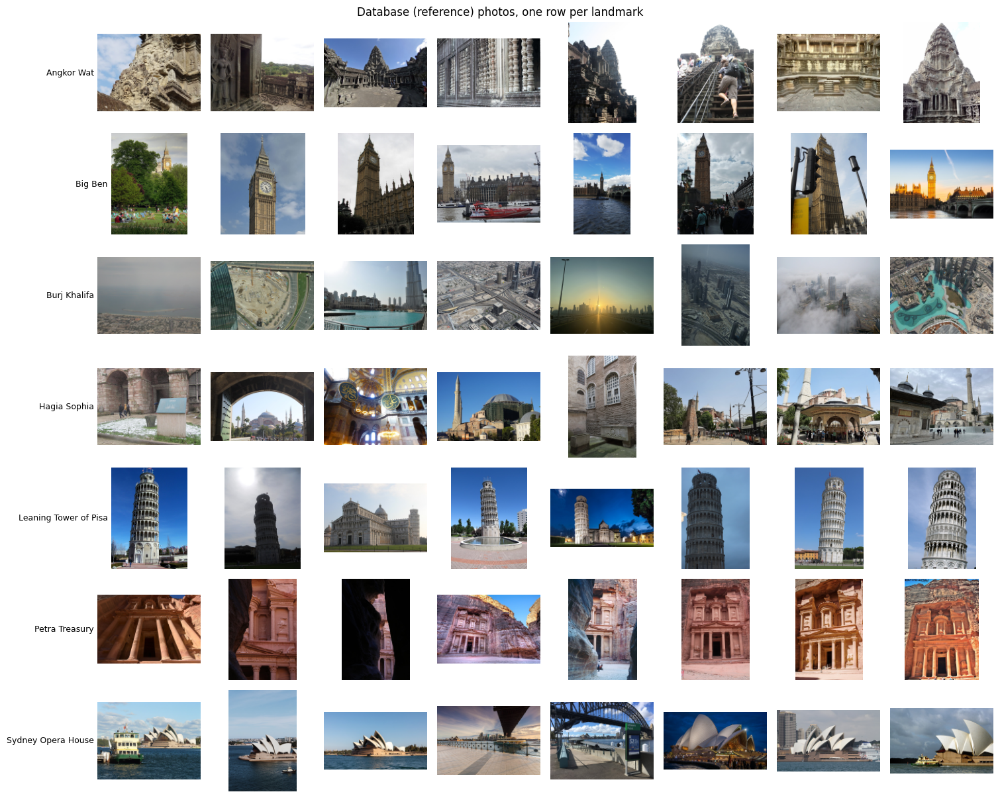

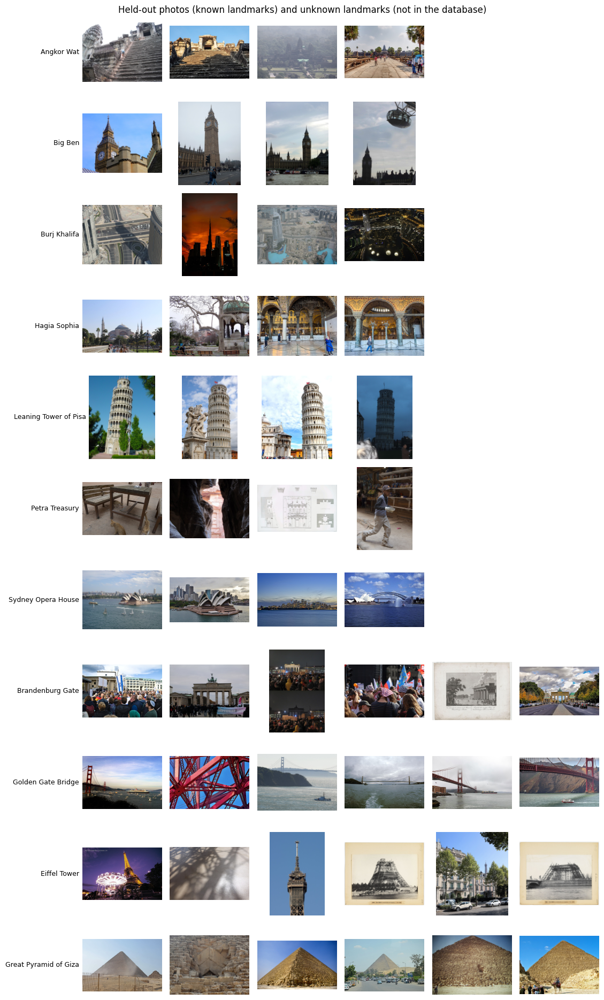


Licences used: {'CC BY 3.0': 9, 'CC BY 4.0': 6, 'CC BY 2.0': 23, 'CC0': 11, 'CC BY-SA 4.0': 38, 'Public domain': 4, 'CC BY-SA 3.0': 12, 'CC BY-SA 2.0': 5}
Authors and licences of every photo are in /content/lab06_data/credits.csv


In [4]:
# ---- index every photo, check the database, and look at what was downloaded ----
DATA_DIR = LOCAL_DATA
rows = []
for role, sub in (("ref", "database"), ("heldout", "queries/known"), ("unk_cal", "queries/unknown_calibration"), ("unk_test", "queries/unknown_test")):
    root = os.path.join(DATA_DIR, sub)
    if not os.path.isdir(root):
        continue
    for lm in sorted(os.listdir(root)):
        d = os.path.join(root, lm)
        if not os.path.isdir(d):
            continue
        for f in sorted(os.listdir(d)):
            if f.lower().endswith((".jpg", ".jpeg", ".png")):
                rows.append(dict(role=role, landmark=lm, file=f, path=os.path.join(d, f), image_id=f"{role}/{lm}/{os.path.splitext(f)[0]}"))
IMAGES = pd.DataFrame(rows)
KNOWN = sorted(IMAGES.loc[IMAGES["role"] == "ref", "landmark"].unique())
assert len(KNOWN) >= 5, f"The database needs at least 5 landmarks, found {len(KNOWN)}."
REF_IDS = IMAGES.loc[IMAGES["role"] == "ref", "image_id"].tolist()
REF_LM = dict(zip(IMAGES["image_id"], IMAGES["landmark"]))

DATASET_SIG = hashlib.md5("|".join(f"{r.image_id}:{os.path.getsize(r.path)}" for r in IMAGES.itertuples()).encode()).hexdigest()[:10]
if EXTRAS.get("dataset_sig") not in (None, DATASET_SIG):
    print("The photos changed since the last run (you removed or replaced some). Old features and results are cleared.")
    QRES.reset()
    for f in ("features.joblib",):
        p = os.path.join(CKPT_DIR, f)
        if os.path.exists(p): os.remove(p)
EXTRAS.set("dataset_sig", DATASET_SIG)

print(f"{len(IMAGES)} photos, {len(KNOWN)} known landmarks: {KNOWN}")
print(pd.crosstab(IMAGES["landmark"], IMAGES["role"]).reindex(columns=["ref", "heldout", "unk_cal", "unk_test"], fill_value=0).to_string())

def contact_sheet(df, title, fname, ncols, thumb=150):
    lms = list(dict.fromkeys(df["landmark"]))
    fig, axes = plt.subplots(len(lms), ncols, figsize=(1.9 * ncols, 1.75 * len(lms)), squeeze=False)
    for r, lm in enumerate(lms):
        sub = df[df["landmark"] == lm].reset_index(drop=True)
        for c in range(ncols):
            ax = axes[r, c]
            if c < len(sub):
                img = cv2.imread(sub.at[c, "path"]); h, w = img.shape[:2]; s = thumb / max(h, w)
                ax.imshow(cv2.cvtColor(cv2.resize(img, None, fx=s, fy=s, interpolation=cv2.INTER_AREA), cv2.COLOR_BGR2RGB))
            _clean_axis(ax)
        axes[r, 0].set_ylabel(lm, rotation=0, ha="right", va="center", fontsize=9)
    plt.suptitle(title); plt.tight_layout(); save_fig(fname); plt.show()

contact_sheet(IMAGES[IMAGES["role"] == "ref"], "Database (reference) photos, one row per landmark", "t1_database_contact_sheet", ncols=int(IMAGES[IMAGES["role"] == "ref"].groupby("landmark").size().max()))
others = IMAGES[IMAGES["role"] != "ref"]
contact_sheet(others, "Held-out photos (known landmarks) and unknown landmarks (not in the database)", "t1_queries_contact_sheet", ncols=int(others.groupby("landmark").size().max()))

cred_path = os.path.join(DATA_DIR, "credits.csv")
if os.path.exists(cred_path):
    cred = pd.read_csv(cred_path)
    print("\nLicences used:", dict(Counter(cred["license"].fillna("unknown"))))
    print("Authors and licences of every photo are in", cred_path)

## 4. Task 2: SIFT feature extraction

**In plain words.** You cannot compare two photos of the same building pixel by pixel: the camera moved, the size changed, the light is different. SIFT (Scale-Invariant Feature Transform, Lowe 2004) avoids this by describing a photo with a few hundred to a few thousand **keypoints**. A keypoint is a small spot (a window corner, a carving, a blob) that is easy to find again. Every keypoint gets **128 numbers**, its *descriptor*, which describe the neighbourhood. If two photos show the same spot, the two descriptors are close to each other, even when one photo is bigger, turned or darker.

SIFT builds the keypoints in four steps:

1. **Find spots at every size.** Blur the photo more and more, then subtract neighbouring blur levels (Difference of Gaussians, "DoG"). A spot of a given size shows up strongest at the blur level that matches its size. A keypoint is a pixel that is the biggest or the smallest among its 26 neighbours (8 in its own level and 9 in each of the levels above and below). This is what makes SIFT **scale invariant**.
2. **Keep only good ones.** Spots with weak contrast (probably noise) and spots that lie on a straight edge (they can slide along the edge, so their position is not exact) are dropped. In code these are `contrastThreshold` and `edgeThreshold`.
3. **Give each keypoint a direction.** Look at which way brightness changes around the keypoint, collect those directions in a 36-bin histogram and take the strongest as the keypoint's own "up". The neighbourhood is then read relative to that direction, which makes SIFT **rotation invariant**.
4. **Describe the neighbourhood.** Take the rotated square around the keypoint and cut it into a 4 x 4 grid. In every cell, measure how much brightness change points in each of 8 directions. 4 x 4 x 8 = **128 numbers**. The vector is normalised, so a darker or lower-contrast photo gives almost the same descriptor (illumination is handled *partly*, not completely).

**Lab steps 1 to 5 in the code below:** load each reference image, convert it to grayscale, detect keypoints, extract descriptors, display the keypoints, and store the descriptors with their landmark labels (the `FEATS` dictionary, saved to Drive).

In [5]:
import joblib

SIFT_CFG = CONFIG["sift"]

def make_sift():
    return cv2.SIFT_create(nfeatures=SIFT_CFG["nfeatures"], nOctaveLayers=SIFT_CFG["nOctaveLayers"],
                           contrastThreshold=SIFT_CFG["contrastThreshold"], edgeThreshold=SIFT_CFG["edgeThreshold"],
                           sigma=SIFT_CFG["sigma"])

SIFT = make_sift()

def limit_side(img, max_side):
    h, w = img.shape[:2]
    s = max(h, w)
    if s > max_side:
        img = cv2.resize(img, (round(w * max_side / s), round(h * max_side / s)), interpolation=cv2.INTER_AREA)
    return img

def load_bgr(path):
    img = cv2.imread(path, cv2.IMREAD_COLOR)
    if img is None:
        raise ValueError(f"cannot read the image {path}")
    return limit_side(img, SIFT_CFG["max_side"])

def extract_features(bgr):
    '''Steps 1 to 4 of the lab: grayscale, SIFT keypoints, descriptors. Keypoints are kept as plain arrays.'''
    gray = cv2.cvtColor(bgr, cv2.COLOR_BGR2GRAY)
    t0 = time.perf_counter()
    kps, desc = SIFT.detectAndCompute(gray, None)
    dt = time.perf_counter() - t0
    if desc is None:
        kps, desc = [], np.zeros((0, 128), np.float32)
    return dict(pt=np.float32([k.pt for k in kps]).reshape(-1, 2), size=np.float32([k.size for k in kps]),
                angle=np.float32([k.angle for k in kps]), response=np.float32([k.response for k in kps]),
                octave=np.int32([k.octave for k in kps]), desc=desc.astype(np.float32), shape=gray.shape, t_sift=dt)

def kps_of(feat, idx=None):
    '''Rebuild OpenCV KeyPoint objects (needed only for drawing).'''
    idx = range(len(feat["pt"])) if idx is None else idx
    return [cv2.KeyPoint(float(feat["pt"][i][0]), float(feat["pt"][i][1]), float(feat["size"][i]),
                         float(feat["angle"][i]), float(feat["response"][i]), int(feat["octave"][i])) for i in idx]

FEAT_PATH = os.path.join(CKPT_DIR, "features.joblib")
FEATS = joblib.load(FEAT_PATH) if os.path.exists(FEAT_PATH) else {}
wanted = set(IMAGES["image_id"])
FEATS = {k: v for k, v in FEATS.items() if k in wanted}
todo = [r for r in IMAGES.itertuples() if r.image_id not in FEATS]
if todo:
    t0 = time.time()
    for n, r in enumerate(todo, start=1):
        FEATS[r.image_id] = extract_features(load_bgr(r.path))
        if n % 25 == 0 or n == len(todo):
            print(f"  SIFT features: {n}/{len(todo)} photos ({time.time() - t0:.0f}s)", flush=True)
    joblib.dump(FEATS, FEAT_PATH, compress=3)
else:
    print("SIFT features already done, loaded from the checkpoint folder.")

stats = []
for role, name in (("ref", "database"), ("heldout", "held-out"), ("unk_cal", "unknown (calibration)"), ("unk_test", "unknown (test)")):
    ids = IMAGES.loc[IMAGES["role"] == role, "image_id"]
    if len(ids) == 0:
        continue
    kp = np.array([len(FEATS[i]["pt"]) for i in ids]); ts = np.array([FEATS[i]["t_sift"] for i in ids])
    stats.append(dict(group=name, photos=len(ids), keypoints_min=int(kp.min()), keypoints_median=int(np.median(kp)),
                      keypoints_max=int(kp.max()), sift_ms_mean=round(1000 * ts.mean(), 1)))
print("\nKeypoints per photo (max side %d px, at most %d keypoints kept):" % (SIFT_CFG["max_side"], SIFT_CFG["nfeatures"]))
print(pd.DataFrame(stats).to_string(index=False))
print("\nOne descriptor has", FEATS[REF_IDS[0]]["desc"].shape[1], "numbers; the first reference photo has", len(FEATS[REF_IDS[0]]["pt"]), "keypoints, so its descriptor array has shape", FEATS[REF_IDS[0]]["desc"].shape)

SIFT features already done, loaded from the checkpoint folder.

Keypoints per photo (max side 800 px, at most 1500 keypoints kept):
                group  photos  keypoints_min  keypoints_median  keypoints_max  sift_ms_mean
             database      56            218              1500           1502         158.8
             held-out      28            399              1500           1501         159.6
unknown (calibration)      12            737              1500           1501         141.9
       unknown (test)      12            271              1500           1502         165.1

One descriptor has 128 numbers; the first reference photo has 1500 keypoints, so its descriptor array has shape (1500, 128)


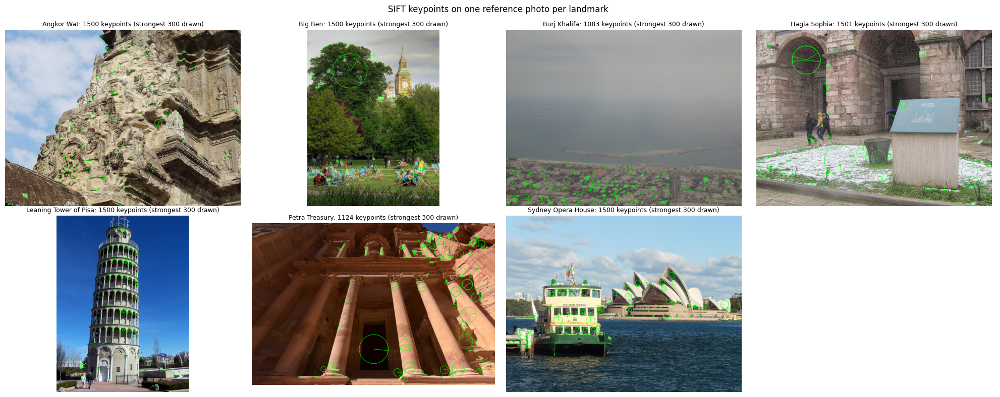

In [6]:
# Lab step 4: reference images with their detected keypoints (circle size = keypoint scale, line = keypoint direction)
def draw_keypoints(bgr, feat, top=None):
    idx = np.argsort(-feat["response"])[:top] if top else None
    return cv2.drawKeypoints(bgr, kps_of(feat, idx), None, color=(0, 255, 0), flags=cv2.DRAW_MATCHES_FLAGS_DRAW_RICH_KEYPOINTS)

firsts = [IMAGES[(IMAGES["role"] == "ref") & (IMAGES["landmark"] == lm)].iloc[0] for lm in KNOWN]
ncols = 4; nrows = int(np.ceil(len(firsts) / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(5 * ncols, 4 * nrows), squeeze=False)
for ax, r in zip(axes.ravel(), firsts):
    f = FEATS[r.image_id]
    show_bgr(ax, draw_keypoints(load_bgr(r.path), f, top=300), f"{r.landmark}: {len(f['pt'])} keypoints (strongest 300 drawn)")
for ax in axes.ravel()[len(firsts):]:
    ax.axis("off")
plt.suptitle("SIFT keypoints on one reference photo per landmark"); plt.tight_layout()
save_fig("t2_reference_keypoints"); plt.show()

**What to look for.** Keypoints cluster on textured, high-contrast structure (windows, arches, carvings, edges of the roof) and are rare on empty sky or smooth walls. The circles have different sizes: SIFT found spots at many scales. Most photos reach the 1,500-keypoint cap (the median is 1,500 in every group). The few with fewer keypoints are smoother scenes: in this figure the Burj Khalifa photo has 1,083 and the Petra Treasury photo 1,124.

### See it for yourself: three small demos of how SIFT works
These demos are simplified drawings of what SIFT does inside. They use one reference photo and the keypoints we just found.

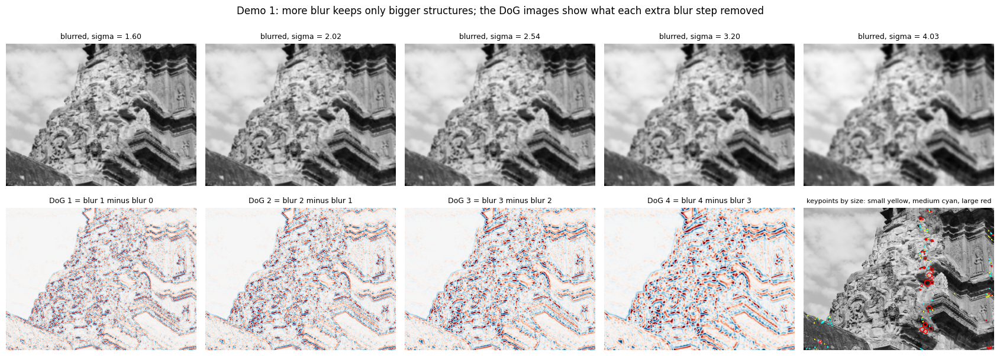

In [7]:
DEMO_REF = firsts[0]
demo_bgr = load_bgr(DEMO_REF.path)
demo_feat = FEATS[DEMO_REF.image_id]

# ---- Demo 1: scale space and Difference of Gaussians (one octave, simplified) ----
gray01 = cv2.cvtColor(demo_bgr, cv2.COLOR_BGR2GRAY).astype(np.float32) / 255.0
k = 2 ** (1 / 3); s0 = SIFT_CFG["sigma"]
sigmas = [s0 * k ** i for i in range(5)]
G = [cv2.GaussianBlur(gray01, (0, 0), s) for s in sigmas]
D = [G[i + 1] - G[i] for i in range(4)]
fig, axes = plt.subplots(2, 5, figsize=(17, 6.4))
for i in range(5):
    axes[0, i].imshow(G[i], cmap="gray"); axes[0, i].set_title(f"blurred, sigma = {sigmas[i]:.2f}", fontsize=9); _clean_axis(axes[0, i])
for i in range(4):
    v = np.percentile(np.abs(D[i]), 99.5) + 1e-9
    axes[1, i].imshow(D[i], cmap="RdBu_r", vmin=-v, vmax=v); axes[1, i].set_title(f"DoG {i + 1} = blur {i + 1} minus blur {i}", fontsize=9); _clean_axis(axes[1, i])
ax = axes[1, 4]
ax.imshow(gray01, cmap="gray")
sizes = demo_feat["size"]; q1, q2 = np.percentile(sizes, [33, 66])
for lo, hi, col in ((0, q1, "yellow"), (q1, q2, "cyan"), (q2, 1e9, "red")):
    for i in np.where((sizes >= lo) & (sizes < hi))[0][:60]:
        ax.add_patch(plt.Circle(demo_feat["pt"][i], demo_feat["size"][i] / 2, fill=False, color=col, lw=0.9))
ax.set_title("keypoints by size: small yellow, medium cyan, large red", fontsize=8); _clean_axis(ax)
plt.suptitle("Demo 1: more blur keeps only bigger structures; the DoG images show what each extra blur step removed")
plt.tight_layout(); save_fig("t2_demo_scale_space"); plt.show()

**What to look for (Demo 1).** The blurred row loses fine detail from left to right. The DoG row (bottom) keeps *only the detail that was erased in that step*: light and dark blobs of about that size. A building that is far away is the same picture at a smaller scale, so its blobs show up at a smaller blur level, and SIFT finds them anyway. That is why the keypoints in the last panel come in small, medium and large sizes.

For the 195 strongest keypoints, OpenCV's direction is within 15 degrees of a strong peak of the simplified histogram in 155 cases (79%).


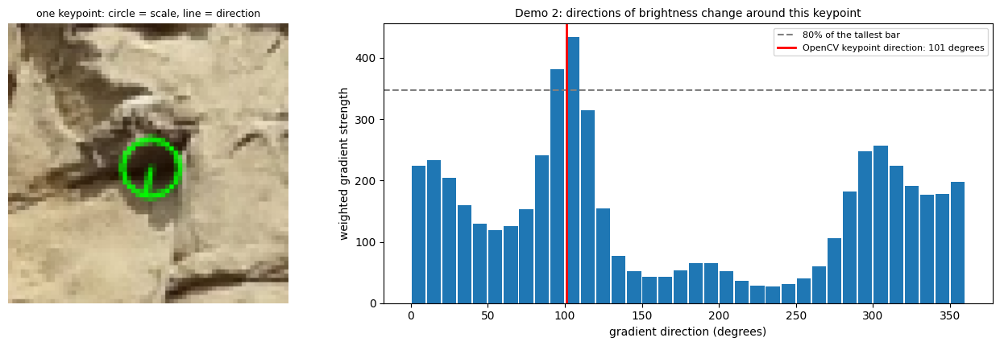

In [8]:
# ---- Demo 2: how a keypoint gets its direction (36-bin gradient histogram, simplified) ----
gray_f = cv2.cvtColor(demo_bgr, cv2.COLOR_BGR2GRAY).astype(np.float32)

def orientation_hist(gray_f, x, y, size, nbins=36):
    sigma = max(size / 2.0, 0.8)
    blur = cv2.GaussianBlur(gray_f, (0, 0), sigma)             # the photo at the keypoint's own scale
    R = max(int(round(4.5 * sigma)), 3)
    H, W = blur.shape; xi, yi = int(round(x)), int(round(y))
    if xi - R - 1 < 0 or yi - R - 1 < 0 or xi + R + 1 >= W or yi + R + 1 >= H:
        return None
    p = blur[yi - R - 1: yi + R + 2, xi - R - 1: xi + R + 2]
    gx = p[1:-1, 2:] - p[1:-1, :-2]; gy = p[2:, 1:-1] - p[:-2, 1:-1]
    mag = np.hypot(gx, gy); ang = np.degrees(np.arctan2(gy, gx)) % 360.0
    yy, xx = np.mgrid[-R:R + 1, -R:R + 1]
    w = np.exp(-(xx ** 2 + yy ** 2) / (2 * (1.5 * sigma) ** 2))   # pixels near the keypoint count more
    h = np.bincount((ang / (360.0 / nbins)).astype(int).ravel() % nbins, weights=(mag * w).ravel(), minlength=nbins)
    h = (np.roll(h, 2) + np.roll(h, -2)) / 16 + 4 * (np.roll(h, 1) + np.roll(h, -1)) / 16 + 6 * h / 16   # light smoothing
    return h

def peak_angles(h, frac=0.8):
    n = len(h)
    return [(i + 0.5) * 360.0 / n for i in range(n) if h[i] >= frac * h.max() and h[i] >= h[i - 1] and h[i] >= h[(i + 1) % n]]

def angle_gap(a, b):
    d = abs(a - b) % 360.0
    return min(d, 360.0 - d)

# how well does this simplified histogram agree with OpenCV's own keypoint directions?
order = np.argsort(-demo_feat["response"])[:200]
agree = total = 0
for i in order:
    h = orientation_hist(gray_f, demo_feat["pt"][i][0], demo_feat["pt"][i][1], demo_feat["size"][i])
    if h is None:
        continue
    total += 1
    agree += any(angle_gap(demo_feat["angle"][i], pk) <= 15 for pk in peak_angles(h))
print(f"For the {total} strongest keypoints, OpenCV's direction is within 15 degrees of a strong peak of the simplified histogram in {agree} cases ({100 * agree / max(total, 1):.0f}%).")

cands = [i for i in order if 10 <= demo_feat["size"][i] <= 45 and orientation_hist(gray_f, demo_feat["pt"][i][0], demo_feat["pt"][i][1], demo_feat["size"][i]) is not None]
i0 = int(cands[0]) if cands else int(order[0])
x0, y0 = demo_feat["pt"][i0]; s0_ = demo_feat["size"][i0]; a0 = demo_feat["angle"][i0]
h0 = orientation_hist(gray_f, x0, y0, s0_)
half = int(max(2.5 * s0_, 30))
x1, y1 = max(int(x0) - half, 0), max(int(y0) - half, 0)
crop = cv2.drawKeypoints(demo_bgr, kps_of(demo_feat, [i0]), None, color=(0, 255, 0), flags=cv2.DRAW_MATCHES_FLAGS_DRAW_RICH_KEYPOINTS)[y1:int(y0) + half, x1:int(x0) + half]
fig, axes = plt.subplots(1, 2, figsize=(13, 4.4), gridspec_kw={"width_ratios": [1, 1.7]})
show_bgr(axes[0], cv2.resize(crop, None, fx=3, fy=3, interpolation=cv2.INTER_NEAREST), "one keypoint: circle = scale, line = direction")
axes[1].bar(np.arange(36) * 10 + 5, h0, width=9, color="tab:blue")
axes[1].axhline(0.8 * h0.max(), color="gray", linestyle="--", label="80% of the tallest bar")
axes[1].axvline(a0, color="red", linewidth=2, label=f"OpenCV keypoint direction: {a0:.0f} degrees")
axes[1].set_xlabel("gradient direction (degrees)"); axes[1].set_ylabel("weighted gradient strength"); axes[1].legend(fontsize=8)
axes[1].set_title("Demo 2: directions of brightness change around this keypoint", fontsize=10)
plt.tight_layout(); save_fig("t2_demo_orientation"); plt.show()

**What to look for (Demo 2).** The bar chart counts, around one keypoint, how strongly the picture changes brightness in each of 36 directions. Usually one bar towers over the rest. That direction (red line) becomes the keypoint's "up". If a second bar is within 80% of the tallest, SIFT creates a second keypoint at the same place with that direction too. Rotating the photo rotates the histogram, the keypoint's "up" turns with it, and the descriptor, which is read *relative to* "up", stays the same. The agreement figure printed above is a self-check of our simplified drawing against what OpenCV really computed; it should be high, and if it is not, treat the drawing as an illustration only.

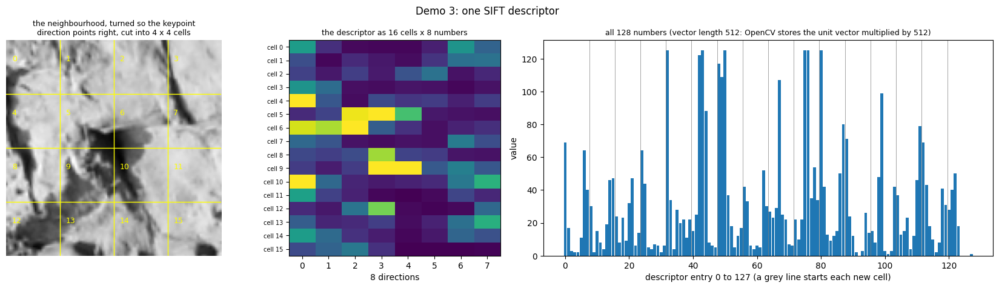

In [9]:
# ---- Demo 3: the 128 numbers of one descriptor ----
def demo_descriptor(bgr, feat, i):
    gray = cv2.cvtColor(bgr, cv2.COLOR_BGR2GRAY)
    x, y = float(feat["pt"][i][0]), float(feat["pt"][i][1]); size = float(feat["size"][i]); ang = float(feat["angle"][i]); d = feat["desc"][i]
    half = 6.0 * size / 2.0                                  # the descriptor reads a square of about 12 x sigma, sigma = size / 2
    P = 128
    M = cv2.getRotationMatrix2D((x, y), ang, P / (2 * half)); M[0, 2] += P / 2 - x; M[1, 2] += P / 2 - y
    patch = cv2.warpAffine(gray, M, (P, P), flags=cv2.INTER_LINEAR, borderMode=cv2.BORDER_REPLICATE)
    fig, axes = plt.subplots(1, 3, figsize=(17, 4.8), gridspec_kw={"width_ratios": [1, 0.8, 1.7]})
    axes[0].imshow(patch, cmap="gray")
    for t in (32, 64, 96):
        axes[0].axhline(t - 0.5, color="yellow", lw=1); axes[0].axvline(t - 0.5, color="yellow", lw=1)
    for r in range(4):
        for c in range(4):
            axes[0].text(c * 32 + 3, r * 32 + 12, str(r * 4 + c), color="yellow", fontsize=9)
    axes[0].set_title("the neighbourhood, turned so the keypoint\ndirection points right, cut into 4 x 4 cells", fontsize=9); _clean_axis(axes[0])
    axes[1].imshow(d.reshape(16, 8), cmap="viridis", aspect="auto")
    axes[1].set_yticks(range(16)); axes[1].set_yticklabels([f"cell {j}" for j in range(16)], fontsize=7)
    axes[1].set_xticks(range(8)); axes[1].set_xlabel("8 directions")
    axes[1].set_title("the descriptor as 16 cells x 8 numbers", fontsize=9)
    axes[2].bar(np.arange(128), d, color="tab:blue", width=0.9)
    for t in range(8, 128, 8):
        axes[2].axvline(t - 0.5, color="gray", lw=0.5)
    axes[2].set_xlabel("descriptor entry 0 to 127 (a grey line starts each new cell)"); axes[2].set_ylabel("value")
    axes[2].set_title(f"all 128 numbers (vector length {np.linalg.norm(d):.0f}: OpenCV stores the unit vector multiplied by 512)", fontsize=9)
    plt.suptitle("Demo 3: one SIFT descriptor"); plt.tight_layout(); save_fig("t2_demo_descriptor"); plt.show()

demo_descriptor(demo_bgr, demo_feat, i0)

**What to look for (Demo 3).** Left: the little square SIFT reads, already turned to the keypoint's own direction and split into 4 x 4 cells. Middle: the descriptor drawn as a table with one row per cell and one column per direction; bright entries mean "lots of brightness change in this direction inside this cell". Right: the same 128 numbers as a bar chart. Two keypoints on the same spot of the same building, even in two different photos, give almost the same bar chart; two different spots give different ones. Matching, in the next sections, is only a way of finding the closest bar charts.

## 5. Task 3: Query image processing

**In plain words.** A visitor's photo is processed in exactly the same way as a reference photo: load, convert to grayscale, find SIFT keypoints, compute descriptors. Nothing else is done to the query. If the query went through different steps than the references (different size, different filters), its descriptors would not be comparable. One detail: every photo, reference or query, is first shrunk so that its longer side is at most 800 pixels. That keeps the work per photo small and puts all photos at a similar working scale.

Query photo: Angkor Wat / angkor_wat_09.jpg
  image size after resizing: 800 x 600 pixels, grayscale array (600, 800)
  keypoints: 1500, descriptors: (1500, 128), SIFT time: 179 ms


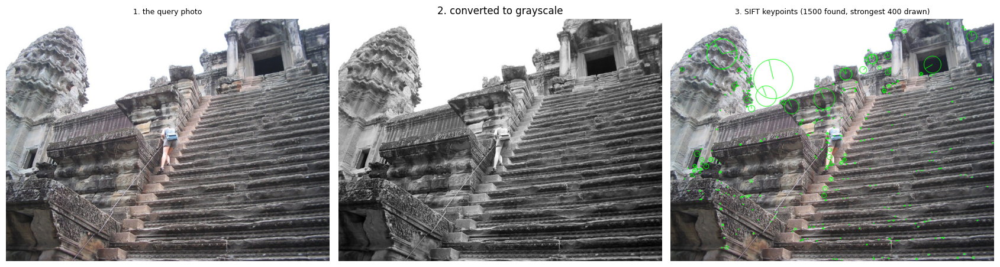

In [10]:
def process_query(source):
    '''Lab task 3, steps 1 to 4. source: file path or a BGR image array. Returns the (resized) image and its SIFT features.'''
    bgr = load_bgr(source) if isinstance(source, str) else limit_side(source, SIFT_CFG["max_side"])
    return bgr, extract_features(bgr)

DEMO_Q = IMAGES[IMAGES["role"] == "heldout"].iloc[0]
qbgr, qfeat = process_query(DEMO_Q.path)
print(f"Query photo: {DEMO_Q.landmark} / {DEMO_Q.file}")
print(f"  image size after resizing: {qbgr.shape[1]} x {qbgr.shape[0]} pixels, grayscale array {qfeat['shape']}")
print(f"  keypoints: {len(qfeat['pt'])}, descriptors: {qfeat['desc'].shape}, SIFT time: {1000 * qfeat['t_sift']:.0f} ms")

fig, axes = plt.subplots(1, 3, figsize=(17, 5))
show_bgr(axes[0], qbgr, "1. the query photo")
axes[1].imshow(cv2.cvtColor(qbgr, cv2.COLOR_BGR2GRAY), cmap="gray"); axes[1].set_title("2. converted to grayscale"); _clean_axis(axes[1])
show_bgr(axes[2], draw_keypoints(qbgr, qfeat, top=400), f"3. SIFT keypoints ({len(qfeat['pt'])} found, strongest 400 drawn)")
plt.tight_layout(); save_fig("t3_query_processing"); plt.show()

**What to look for.** The query has the same kind of keypoints as the reference photos. Nothing in these pictures says which landmark it is. Recognition only happens when we compare these descriptors with the stored ones (next section).

## 6. Task 4: Feature matching and landmark recognition

**In plain words.** To find out which landmark a query shows, compare the query's descriptors with the stored ones.

- **Brute-force matcher with Euclidean distance.** For one query descriptor, measure the straight-line distance (in the 128-number space) to *every* descriptor of a reference photo. "Brute force" means exactly that: try them all. Nothing clever, but exact.
- **k-nearest-neighbour with k = 2.** Instead of keeping only the closest descriptor, keep the **two** closest. We need the second one for the next step.
- **Lowe's ratio test.** Is the closest match trustworthy? Compare it with the runner-up. If the best is much closer than the second best (`distance_1 < 0.75 x distance_2`), the spot has one clear partner: keep it. If the two are almost equally close (repeated windows, bricks, tiles), the match is a coin flip: discard it. Lowe (2004) reported that a ratio of 0.8 removes about 90% of the false matches while losing fewer than 5% of the correct ones. We use 0.75, slightly stricter.
- **One reference photo at a time.** The query is compared with each reference photo separately and every photo gets its own count of reliable matches. If photos of one landmark were pooled, the same spot would appear in two of them, both "close", and the ratio test would wrongly throw away a good match. A landmark's score is the count of its **best** reference photo.
- **The largest count is not a decision.** The brief says not to classify an image only by the largest match count, and for good reason: a photo of a place we do not know still has a "largest count", an unrelated photo can collect a few matches by chance, and richly textured photos collect more matches than plain ones. So after ranking we also check the matches geometrically (Section 7) and apply thresholds that are measured, not guessed (Section 8).

Demo pair (the clearest of the first held-out photos): query heldout/Hagia Sophia/hagia_sophia_09  vs  reference ref/Hagia Sophia/hagia_sophia_02  (210 reliable matches)
Query keypoints: 1500. Reference keypoints: 1500. Every query descriptor found a nearest neighbour: 1500 raw matches.
After Lowe's ratio test (ratio 0.75): 210 reliable matches kept, 1290 thrown away.


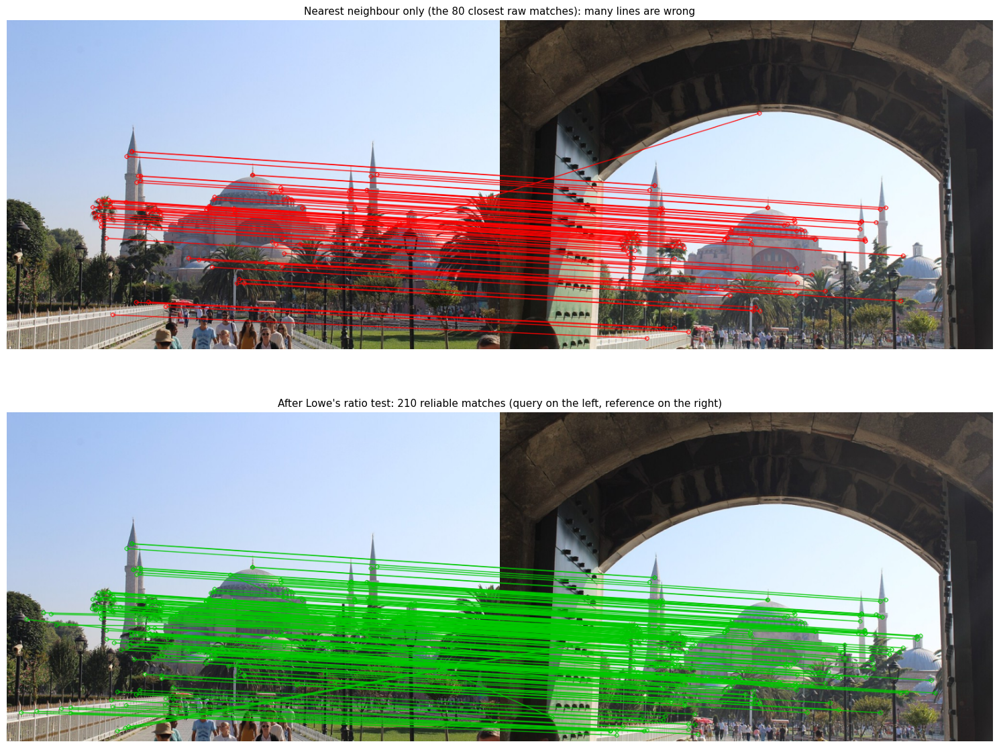

In [11]:
BF = cv2.BFMatcher(cv2.NORM_L2)                # brute force, Euclidean (L2) distance

def knn_two(dq, dr):
    '''For every query descriptor: its two closest reference descriptors. Returns (query idx, reference idx, d1, d2).'''
    if len(dq) == 0 or len(dr) < 2:
        z = np.zeros(0)
        return z.astype(int), z.astype(int), z.astype(np.float32), z.astype(np.float32)
    qi, ri, d1, d2 = [], [], [], []
    for pair in BF.knnMatch(dq, dr, k=2):
        if len(pair) == 2:
            qi.append(pair[0].queryIdx); ri.append(pair[0].trainIdx); d1.append(pair[0].distance); d2.append(pair[1].distance)
    return np.array(qi, int), np.array(ri, int), np.array(d1, np.float32), np.array(d2, np.float32)

def good_matches(dq, dr, ratio=None):
    '''Reliable matches = those that pass Lowe's ratio test.'''
    ratio = CONFIG["ratio"] if ratio is None else ratio
    qi, ri, d1, d2 = knn_two(dq, dr)
    keep = d1 < ratio * d2
    return qi[keep], ri[keep]

PATH_OF = dict(zip(IMAGES["image_id"], IMAGES["path"]))
LM_OF = REF_LM

def landmark_ranking(counts_by_ref):
    '''Landmark score = reliable matches of its best reference photo. Returns [(landmark, best ref id, count)] sorted high to low.'''
    best = {}
    for rid, n in counts_by_ref.items():
        lm = LM_OF[rid]
        if lm not in best or n > best[lm][1]:
            best[lm] = (rid, n)
    return sorted(((lm, rid, n) for lm, (rid, n) in best.items()), key=lambda t: -t[2])

# a clear example for the demos: among the first held-out photo of every landmark, the pair (query, same-landmark reference) with most reliable matches
best_pair, best_n = None, -1
for lm in KNOWN:
    q = IMAGES[(IMAGES["role"] == "heldout") & (IMAGES["landmark"] == lm)]
    if len(q) == 0:
        continue
    qid = q.iloc[0]["image_id"]
    for rid in [r for r in REF_IDS if LM_OF[r] == lm]:
        n = len(good_matches(FEATS[qid]["desc"], FEATS[rid]["desc"])[0])
        if n > best_n:
            best_pair, best_n = (qid, rid), n
PAIR_Q, PAIR_R = best_pair
pq_bgr, pr_bgr = load_bgr(PATH_OF[PAIR_Q]), load_bgr(PATH_OF[PAIR_R])
pq, pr = FEATS[PAIR_Q], FEATS[PAIR_R]
print(f"Demo pair (the clearest of the first held-out photos): query {PAIR_Q}  vs  reference {PAIR_R}  ({best_n} reliable matches)")

qi, ri, d1, d2 = knn_two(pq["desc"], pr["desc"])
keep = d1 < CONFIG["ratio"] * d2
print(f"Query keypoints: {len(pq['pt'])}. Reference keypoints: {len(pr['pt'])}. Every query descriptor found a nearest neighbour: {len(qi)} raw matches.")
print(f"After Lowe's ratio test (ratio {CONFIG['ratio']}): {int(keep.sum())} reliable matches kept, {int((~keep).sum())} thrown away.")

def draw_dmatches(qbgr, qfeat, rbgr, rfeat, qi, ri, d, color):
    dm = [cv2.DMatch(int(a), int(b), float(c)) for a, b, c in zip(qi, ri, d)]
    return cv2.drawMatches(qbgr, kps_of(qfeat), rbgr, kps_of(rfeat), dm, None, matchColor=color, singlePointColor=color,
                           flags=cv2.DRAW_MATCHES_FLAGS_NOT_DRAW_SINGLE_POINTS)

closest = np.argsort(d1)[:80]
fig, axes = plt.subplots(2, 1, figsize=(15, 12))
show_bgr(axes[0], draw_dmatches(pq_bgr, pq, pr_bgr, pr, qi[closest], ri[closest], d1[closest], (0, 0, 255)),
         "Nearest neighbour only (the 80 closest raw matches): many lines are wrong", fontsize=11)
show_bgr(axes[1], draw_dmatches(pq_bgr, pq, pr_bgr, pr, qi[keep], ri[keep], d1[keep], (0, 200, 0)),
         f"After Lowe's ratio test: {int(keep.sum())} reliable matches (query on the left, reference on the right)", fontsize=11)
plt.tight_layout(); save_fig("t4_matches_before_after_ratio_test"); plt.show()

**What to look for.** The top picture draws only the 80 *closest* raw matches. They are mostly right (the lines run between the same parts of the scene), but a few stray lines already appear, for example one from the query's sky to the reference's arch. The ratio test matters most for the other raw matches that are not drawn: of the 1,500 raw matches only 210 survive, and in the bottom picture the survivors are mostly lines between the same parts of the scene. This pair is an easy case: the query and the reference are two photos of the same scene from almost the same position. The next plot shows *why* the ratio test separates right matches from wrong ones.

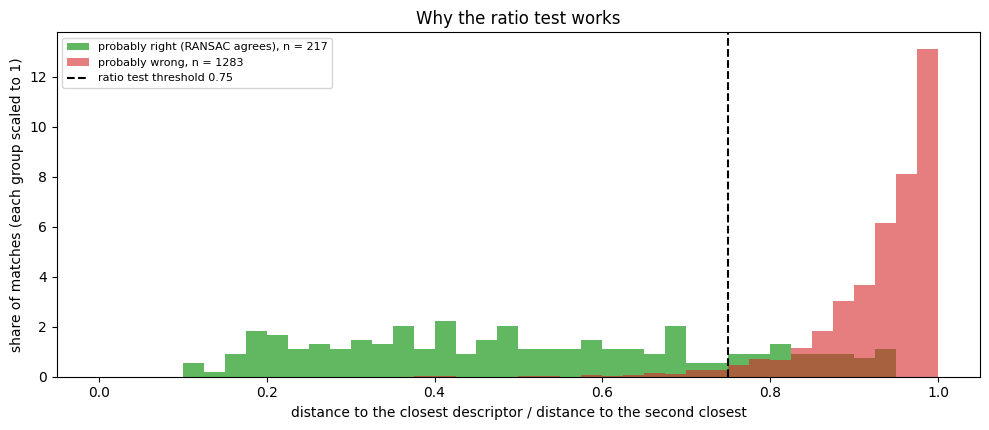

Threshold 0.75 keeps 81% of the probably-right matches and 3% of the probably-wrong ones.
('Probably right' means: RANSAC, which knows nothing about distances, found them consistent. It is a stand-in for the unknown truth.)


In [12]:
# Why does the ratio test work? Compare the ratio d1/d2 of matches that are probably right with those that are probably wrong.
ratio_all = d1 / np.maximum(d2, 1e-6)
loose = ratio_all < 0.95                                   # give RANSAC a generous set of candidates, then see who agrees
src = pr["pt"][ri[loose]].reshape(-1, 1, 2).astype(np.float32); dst = pq["pt"][qi[loose]].reshape(-1, 1, 2).astype(np.float32)
Hs, msk = cv2.findHomography(src, dst, cv2.RANSAC, CONFIG["ransac"]["reproj_threshold"])
probably_right = np.zeros(len(qi), bool)
if msk is not None:
    probably_right[np.where(loose)[0][msk.ravel().astype(bool)]] = True
fig, ax = plt.subplots(figsize=(10, 4.4))
bins = np.linspace(0, 1, 41)
ax.hist(ratio_all[probably_right], bins=bins, alpha=0.75, color="tab:green", density=True, label=f"probably right (RANSAC agrees), n = {int(probably_right.sum())}")
ax.hist(ratio_all[~probably_right], bins=bins, alpha=0.6, color="tab:red", density=True, label=f"probably wrong, n = {int((~probably_right).sum())}")
ax.axvline(CONFIG["ratio"], color="k", linestyle="--", label=f"ratio test threshold {CONFIG['ratio']}")
ax.set_xlabel("distance to the closest descriptor / distance to the second closest"); ax.set_ylabel("share of matches (each group scaled to 1)")
ax.set_title("Why the ratio test works"); ax.legend(fontsize=8)
plt.tight_layout(); save_fig("t4_ratio_distribution"); plt.show()
kept_right = float((ratio_all[probably_right] < CONFIG["ratio"]).mean()) if probably_right.any() else float("nan")
kept_wrong = float((ratio_all[~probably_right] < CONFIG["ratio"]).mean())
print(f"Threshold {CONFIG['ratio']} keeps {100 * kept_right:.0f}% of the probably-right matches and {100 * kept_wrong:.0f}% of the probably-wrong ones.")
print("('Probably right' means: RANSAC, which knows nothing about distances, found them consistent. It is a stand-in for the unknown truth.)")

**What to look for.** The green histogram (matches that a geometry check later accepts) sits at low ratios: the closest descriptor is clearly closer than the second closest. The red histogram (probably wrong matches) sits near 1: the best and second best are nearly the same distance, so the "best" is a guess. A threshold near 0.75 keeps most of the green and removes most of the red. A stricter threshold loses more right matches, a looser one lets in more wrong ones: that is the trade-off Lowe measured.

**Ranking the landmarks (lab steps 4 to 6).** Now compare this query with *all* reference photos, count reliable matches per photo, take each landmark's best photo and rank the landmarks.

Query: heldout/Hagia Sophia/hagia_sophia_09   (true landmark: Hagia Sophia)   matched against 56 reference photos in 3.0 s

 rank              landmark     best_reference_photo  reliable_matches
    1          Hagia Sophia          hagia_sophia_02               210
    2          Burj Khalifa          burj_khalifa_08                32
    3               Big Ben               big_ben_02                31
    4 Leaning Tower of Pisa leaning_tower_of_pisa_06                27
    5        Petra Treasury        petra_treasury_01                25
    6            Angkor Wat            angkor_wat_02                23
    7    Sydney Opera House    sydney_opera_house_07                23

Most likely landmark by reliable matches: Hagia Sophia (210 matches). This is a ranking, not yet a decision.


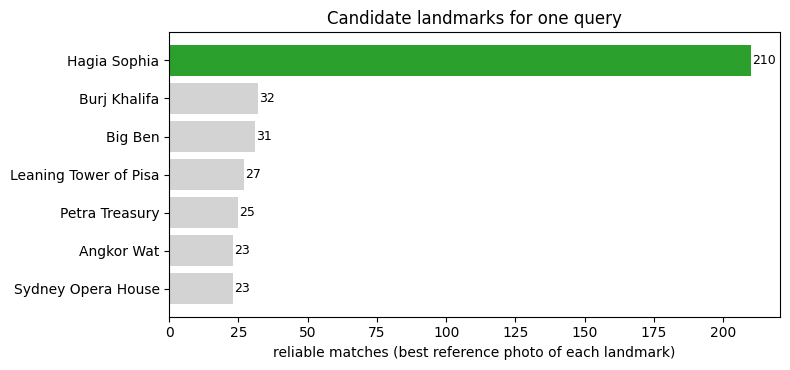

In [13]:
t0 = time.perf_counter()
counts = {rid: len(good_matches(pq["desc"], FEATS[rid]["desc"])[0]) for rid in REF_IDS}
t_rank = time.perf_counter() - t0
rank = landmark_ranking(counts)
print(f"Query: {PAIR_Q}   (true landmark: {LM_OF[PAIR_Q]})   matched against {len(REF_IDS)} reference photos in {t_rank:.1f} s\n")
print(pd.DataFrame([dict(rank=i + 1, landmark=lm, best_reference_photo=rid.split("/")[-1], reliable_matches=n) for i, (lm, rid, n) in enumerate(rank)]).to_string(index=False))
print(f"\nMost likely landmark by reliable matches: {rank[0][0]} ({rank[0][2]} matches). This is a ranking, not yet a decision.")

fig, ax = plt.subplots(figsize=(8, 3.8))
names = [r[0] for r in rank][::-1]; vals = [r[2] for r in rank][::-1]
ax.barh(names, vals, color=["tab:green" if n == rank[0][0] else "lightgray" for n in names])
for y, v in enumerate(vals):
    ax.text(v + 0.3, y, str(v), va="center", fontsize=9)
ax.set_xlabel("reliable matches (best reference photo of each landmark)"); ax.set_title("Candidate landmarks for one query")
plt.tight_layout(); save_fig("t4_candidate_ranking"); plt.show()

**What to look for.** One landmark should stand clearly above the others. The wrong landmarks still collect a few reliable-looking matches by chance: that background level is exactly what a threshold must stay above. How high it is, and how it changes for an unknown place, is measured in Section 8.

## 7. Task 5: Landmark localization (RANSAC and homography)

**In plain words.** Even after the ratio test, some matches are wrong. But the *correct* matches all tell the same story: the reference photo and the query show the same thing, so every right match moves according to **one common transformation**. For a flat surface seen from two positions that transformation is a **homography**: a 3 x 3 matrix `H` that sends every point (x, y) of the reference photo to a point (x', y') in the query photo (it captures shift, rotation, scale and perspective at once). Matches that do not follow the story are wrong.

**RANSAC** (RANdom SAmple Consensus) finds the story in spite of the wrong matches. Repeat many times: pick 4 random matches (the minimum that fixes a homography), compute `H` from them, then count how many of the other matches agree with it. A match **agrees** (is an **inlier**) if the projected reference point lands within 5 pixels of its partner in the query. Keep the `H` with the most inliers. Wrong matches are scattered at random, so they rarely agree with any one `H`; right matches all agree with the true one. Normal "least squares" fitting would be dragged off by the wrong matches, which is why RANSAC is used.

**Localization.** With `H`, project the four corners of the reference photo into the query: the polygon shows where the reference content sits in the query. **Two honest warnings.** A building is 3D, so one flat `H` fits well only for moderate viewpoint changes (or distant buildings); for big changes the story breaks. And a bad `H` gives nonsense polygons, so we check the polygon (convex? sensible size? sensible angles?) and, if it fails, show a message instead of drawing it.

First a toy version you can see: fit a straight line to points where 40% are wrong.

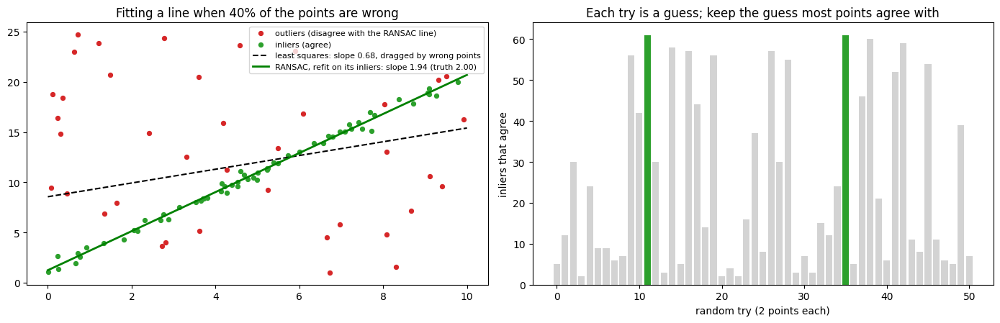

Least squares slope 0.68, RANSAC slope 1.94, true slope 2.00. The best of 51 guesses had 61 of 100 points agreeing.


In [14]:
rng = np.random.RandomState(7)
x_in = rng.uniform(0, 10, 60); y_in = 2 * x_in + 1 + rng.normal(0, 0.4, 60)          # 60 points that follow the rule y = 2x + 1
x_out = rng.uniform(0, 10, 40); y_out = rng.uniform(0, 25, 40)                         # 40 wrong points
X = np.r_[x_in, x_out]; Y = np.r_[y_in, y_out]
ls_m, ls_b = np.polyfit(X, Y, 1)                                                       # ordinary least squares
tries, best = [], (-1, None)
for it in range(60):
    i, j = rng.choice(len(X), 2, replace=False)                                        # a line needs 2 points (a homography needs 4)
    if abs(X[i] - X[j]) < 0.5:
        continue
    m = (Y[j] - Y[i]) / (X[j] - X[i]); b = Y[i] - m * X[i]
    inl = np.abs(Y - (m * X + b)) < 1.0
    tries.append(int(inl.sum()))
    if inl.sum() > best[0]:
        best = (int(inl.sum()), (m, b, inl))
m_r, b_r, inl_r = best[1]
m_r, b_r = np.polyfit(X[inl_r], Y[inl_r], 1)                                         # last RANSAC step: refit using only the inliers
fig, axes = plt.subplots(1, 2, figsize=(14, 4.6))
axes[0].scatter(X[~inl_r], Y[~inl_r], c="tab:red", s=18, label="outliers (disagree with the RANSAC line)")
axes[0].scatter(X[inl_r], Y[inl_r], c="tab:green", s=18, label="inliers (agree)")
xs = np.array([0, 10])
axes[0].plot(xs, ls_m * xs + ls_b, "k--", label=f"least squares: slope {ls_m:.2f}, dragged by wrong points")
axes[0].plot(xs, m_r * xs + b_r, "g-", lw=2, label=f"RANSAC, refit on its inliers: slope {m_r:.2f} (truth 2.00)")
axes[0].legend(fontsize=8); axes[0].set_title("Fitting a line when 40% of the points are wrong")
axes[1].bar(range(len(tries)), tries, color=["tab:green" if t == best[0] else "lightgray" for t in tries])
axes[1].set_xlabel("random try (2 points each)"); axes[1].set_ylabel("inliers that agree"); axes[1].set_title("Each try is a guess; keep the guess most points agree with")
plt.tight_layout(); save_fig("t5_ransac_toy_demo"); plt.show()
print(f"Least squares slope {ls_m:.2f}, RANSAC slope {m_r:.2f}, true slope 2.00. The best of {len(tries)} guesses had {best[0]} of 100 points agreeing.")

**What to look for.** The dashed least-squares line is pulled towards the wrong points; the RANSAC line recovers the true rule. RANSAC never "removes" outliers explicitly; it just trusts the guess that most points support. A homography works the same way with 4 matches per guess and "agree" meaning "within 5 pixels after projection".

Reliable matches: 210   RANSAC inliers: 175   inlier share: 83%
Homography H (reference -> query):
 [[ 1.03870e+00 -5.86000e-02 -5.01470e+01]
 [ 1.38000e-02  9.34000e-01 -4.80226e+01]
 [ 0.00000e+00 -2.00000e-04  1.00000e+00]]
Projected corners of the reference photo in the query: [[-50.0, -48.0], [757.0, -36.0], [799.0, 491.0], [-90.0, 496.0]] | outline check: True - ok


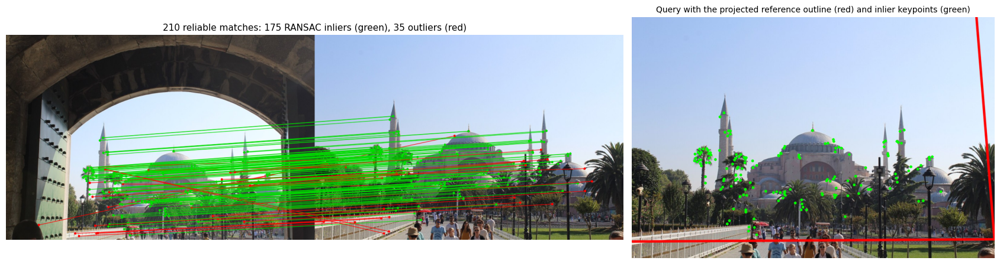

In [15]:
RANSAC_CFG = CONFIG["ransac"]; POLY_CFG = CONFIG["polygon"]

def ransac_verify(qpt, rpt, qi, ri):
    '''Homography reference -> query with RANSAC. Returns (H or None, boolean inlier mask over the given matches).'''
    n = len(qi)
    if n < RANSAC_CFG["min_matches"]:
        return None, np.zeros(n, bool)
    src = rpt[ri].reshape(-1, 1, 2).astype(np.float32)
    dst = qpt[qi].reshape(-1, 1, 2).astype(np.float32)
    H, mask = cv2.findHomography(src, dst, cv2.RANSAC, RANSAC_CFG["reproj_threshold"],
                                 maxIters=RANSAC_CFG["max_iters"], confidence=RANSAC_CFG["confidence"])
    if H is None or mask is None:
        return None, np.zeros(n, bool)
    return H, mask.ravel().astype(bool)

def project_corners(H, ref_shape):
    h, w = ref_shape
    c = np.float32([[0, 0], [w, 0], [w, h], [0, h]]).reshape(-1, 1, 2)
    return cv2.perspectiveTransform(c, H).reshape(-1, 2)

def interior_angles(poly):
    out = []
    for i in range(4):
        a, b = poly[i - 1] - poly[i], poly[(i + 1) % 4] - poly[i]
        c = np.dot(a, b) / (np.linalg.norm(a) * np.linalg.norm(b) + 1e-9)
        out.append(float(np.degrees(np.arccos(np.clip(c, -1, 1)))))
    return out

def polygon_check(poly, q_shape):
    '''Is the projected outline believable? Returns (ok, reason). Four plain-sense checks.'''
    if not np.all(np.isfinite(poly)):
        return False, "the corners are not finite numbers"
    contour = poly.astype(np.float32).reshape(-1, 1, 2)
    area = float(cv2.contourArea(contour)); area_q = float(q_shape[0] * q_shape[1])
    if not cv2.isContourConvex(contour):
        return False, "the outline is twisted (not convex)"
    if area < POLY_CFG["min_area_frac"] * area_q:
        return False, "the outline is tiny"
    if area > POLY_CFG["max_area_frac"] * area_q:
        return False, "the outline is far larger than the photo"
    sides = np.linalg.norm(np.roll(poly, -1, axis=0) - poly, axis=1)
    if sides.max() / max(sides.min(), 1e-6) > POLY_CFG["max_side_ratio"]:
        return False, "the outline is extremely stretched"
    ang = interior_angles(poly)
    if min(ang) < POLY_CFG["min_angle"] or max(ang) > POLY_CFG["max_angle"]:
        return False, "the outline has extreme corner angles"
    return True, "ok"

def side_by_side(rbgr, qbgr):
    h = max(rbgr.shape[0], qbgr.shape[0])
    canvas = np.zeros((h, rbgr.shape[1] + qbgr.shape[1], 3), np.uint8)
    canvas[:rbgr.shape[0], :rbgr.shape[1]] = rbgr; canvas[:qbgr.shape[0], rbgr.shape[1]:] = qbgr
    return canvas, rbgr.shape[1]

def ip(p):
    return (int(round(float(p[0]))), int(round(float(p[1]))))

def draw_match_lines(rbgr, qbgr, rpt, qpt, ri, qi, inlier_mask, max_lines=160):
    '''Reference on the left, query on the right. Green = RANSAC inlier, red = outlier.'''
    canvas, off = side_by_side(rbgr, qbgr)
    idx = np.arange(len(qi))
    if len(idx) > max_lines:
        idx = np.random.RandomState(0).choice(idx, max_lines, replace=False)
    for j in idx:
        p1, p2 = ip(rpt[ri[j]]), ip(qpt[qi[j]] + np.array([off, 0]))
        col = (0, 220, 0) if inlier_mask[j] else (0, 0, 255)
        cv2.line(canvas, p1, p2, col, 1, cv2.LINE_AA); cv2.circle(canvas, p1, 3, col, -1); cv2.circle(canvas, p2, 3, col, -1)
    return canvas

qi_g, ri_g = good_matches(pq["desc"], pr["desc"])
H, inl = ransac_verify(pq["pt"], pr["pt"], qi_g, ri_g)
n_in = int(inl.sum())
print(f"Reliable matches: {len(qi_g)}   RANSAC inliers: {n_in}   inlier share: {100 * n_in / max(len(qi_g), 1):.0f}%")
poly = None
if H is not None:
    print("Homography H (reference -> query):\n", np.round(H, 4))
    poly = project_corners(H, pr["shape"])
    ok, why = polygon_check(poly, pq["shape"])
    print("Projected corners of the reference photo in the query:", np.round(poly, 0).tolist(), "| outline check:", ok, "-", why)

fig, axes = plt.subplots(1, 2, figsize=(17, 5.6), gridspec_kw={"width_ratios": [1.7, 1]})
show_bgr(axes[0], draw_match_lines(pr_bgr, pq_bgr, pr["pt"], pq["pt"], ri_g, qi_g, inl),
         f"{len(qi_g)} reliable matches: {n_in} RANSAC inliers (green), {len(qi_g) - n_in} outliers (red)", fontsize=11)
canvas = pq_bgr.copy()
if H is not None and ok:
    cv2.polylines(canvas, [np.round(poly).astype(np.int32).reshape(-1, 1, 2)], True, (0, 0, 255), 4, cv2.LINE_AA)
    for p in pq["pt"][qi_g[inl]]:
        cv2.circle(canvas, ip(p), 3, (0, 255, 0), -1)
    title = "Query with the projected reference outline (red) and inlier keypoints (green)"
else:
    title = "Outline NOT drawn: " + (why if H is not None else "no homography could be estimated")
show_bgr(axes[1], canvas, title, fontsize=10)
plt.tight_layout(); save_fig("t5_ransac_and_polygon_demo"); plt.show()

**What to look for.** Left: most reliable matches are green (inliers), a few are red. The red lines are matches the ratio test let through but that disagree with the common transformation: RANSAC caught them. Right: the red outline is where the *whole reference photo* lands inside the query, so it includes sky and surroundings, not just the building. The green dots (inlier keypoints) show where the match evidence actually lies. If the outline looks wrong or is missing, the printed check says why. In this clear example the query and the reference show the same scene from almost the same position, so the outline almost coincides with the photo border.

## 8. Putting it together: the decision rule and how its thresholds are chosen

**In plain words.** So far we can *rank* landmarks. The system must also *decide*: recognise a landmark, or say "I do not know this place". The brief asks for a defined matching threshold and says not to trust the largest count alone. The decision here has three checks, and a landmark is accepted only if all three pass:

1. **Enough reliable matches** after the ratio test (`t_good`).
2. **Enough RANSAC inliers**, i.e. matches that also agree geometrically (`t_inliers`). This is the strongest check: chance matches rarely line up.
3. **A clear margin over the runner-up**: the best landmark must have at least `margin` times the inliers of the second-best landmark. If two landmarks look equally good, we do not guess.

The pipeline for one query: SIFT on the query, match against every reference photo, rank landmarks by reliable matches (Task 4), run RANSAC on the **top 3 landmarks** (the best reference photo of each), pick the landmark with the most inliers, then apply the three checks.

**Where do the numbers `t_good`, `t_inliers`, `margin` come from?** They are measured, not guessed. We try many combinations on a **calibration set** where we know the right answer:
- *Known photos:* every database photo used as a query against the **other** database photos (leave-one-out; if the photo itself stayed in the database it would match itself perfectly).
- *Unknown photos:* pictures of two places that are not in the database.

From all combinations we keep those that accept (almost) none of the unknown photos and name a wrong landmark for at most 2% of the known photos. Among those, the ones that recognise the most known photos win. Many combinations tie, so we take the one in the **middle of that safe zone**, not on its edge. The test photos play no part in this choice.

In [16]:
def analyse_query(qfeat, exclude_id=None, keep_matches=False):
    '''The whole recognition pipeline for one query (given its SIFT features).
    Returns a plain dictionary of numbers (so it can be saved and re-used with other thresholds).'''
    t0 = time.perf_counter()
    per_ref = {}
    for rid in REF_IDS:
        if rid != exclude_id:
            per_ref[rid] = good_matches(qfeat["desc"], FEATS[rid]["desc"])
    t_match = time.perf_counter() - t0
    rank = landmark_ranking({rid: len(v[0]) for rid, v in per_ref.items()})
    t0 = time.perf_counter()
    verified = []
    for lm, rid, n_good in rank[:CONFIG["verify_top_landmarks"]]:
        qi, ri = per_ref[rid]
        H, mask = ransac_verify(qfeat["pt"], FEATS[rid]["pt"], qi, ri)
        n_in = int(mask.sum()); poly, ok, why = None, False, "no homography could be estimated"
        if H is not None and n_in >= 4:
            poly = project_corners(H, FEATS[rid]["shape"]); ok, why = polygon_check(poly, qfeat["shape"])
        verified.append(dict(landmark=lm, ref=rid, n_good=int(n_good), n_inliers=n_in,
                             inlier_ratio=(n_in / n_good if n_good else 0.0), poly_ok=bool(ok), poly_reason=why,
                             poly=None if poly is None else np.round(poly, 1).tolist()))
    verified.sort(key=lambda v: (-v["n_inliers"], -v["n_good"]))
    t_ransac = time.perf_counter() - t0
    res = dict(n_kp=int(len(qfeat["pt"])), t_sift=float(qfeat["t_sift"]), t_match=float(t_match), t_ransac=float(t_ransac),
               t_total=float(qfeat["t_sift"] + t_match + t_ransac),
               ranking=[dict(landmark=lm, ref=rid, n_good=int(n)) for lm, rid, n in rank], verified=verified)
    return (res, per_ref) if keep_matches else res

def decide(res, thr):
    '''Apply the three checks. thr = {"t_good", "t_inliers", "margin"}.'''
    v = res["verified"]
    count_winner = res["ranking"][0]["landmark"] if res["ranking"] else None
    if not v:
        return dict(decision="REJECTED", predicted=None, candidate=None, reason="no candidate", count_winner=count_winner)
    best, runner = v[0], (v[1] if len(v) > 1 else None)
    why = []
    if best["n_good"] < thr["t_good"]:
        why.append(f"only {best['n_good']} reliable matches (need {thr['t_good']})")
    if best["n_inliers"] < thr["t_inliers"]:
        why.append(f"only {best['n_inliers']} RANSAC inliers (need {thr['t_inliers']})")
    if runner is not None and best["n_inliers"] < thr["margin"] * max(runner["n_inliers"], 1):
        why.append(f"not clearly ahead of {runner['landmark']} ({best['n_inliers']} against {runner['n_inliers']} inliers, need x{thr['margin']})")
    ok = not why
    return dict(decision="RECOGNIZED" if ok else "REJECTED", predicted=best["landmark"] if ok else None, candidate=best["landmark"],
                reason="all checks passed" if ok else "; ".join(why), count_winner=count_winner)

def run_batch(df, kind, exclude_self=False):
    '''Analyse every photo of df and save the results (resumes after a disconnect).'''
    todo = [r for r in df.itertuples() if f"{kind}/{r.image_id}" not in QRES.data]
    if not todo:
        print(f"[{kind}] already done ({len(df)} photos)"); return
    t0 = time.time()
    for n, r in enumerate(todo, start=1):
        QRES.put(f"{kind}/{r.image_id}", analyse_query(FEATS[r.image_id], exclude_id=r.image_id if exclude_self else None))
        if n % 10 == 0 or n == len(todo):
            QRES.flush(); print(f"  [{kind}] {n}/{len(todo)} photos ({time.time() - t0:.0f}s)", flush=True)

cal_pos = IMAGES[IMAGES["role"] == "ref"]
cal_neg = IMAGES[IMAGES["role"] == "unk_cal"]
run_batch(cal_pos, "loo", exclude_self=True)
run_batch(cal_neg, "cal_unknown")
POS = [(QRES.get(f"loo/{r.image_id}"), r.landmark) for r in cal_pos.itertuples()]
NEG = [(QRES.get(f"cal_unknown/{r.image_id}"), None) for r in cal_neg.itertuples()]
print(f"Calibration set: {len(POS)} known photos (leave-one-out) and {len(NEG)} unknown photos.")

[loo] already done (56 photos)
[cal_unknown] already done (12 photos)
Calibration set: 56 known photos (leave-one-out) and 12 unknown photos.


196 threshold combinations accept at most 0% of the unknown photos and name a wrong landmark for at most 2% of the known ones;
12 of them recognise the most known photos (23.2%). Taking the one in the middle of that group.

Chosen thresholds: {'t_good': 12, 't_inliers': 6, 'margin': 1.5}
On the calibration data they recognise 23.2% of known photos, name a wrong landmark for 0.0%, and accept 0.0% of unknown photos.
For comparison, a common rule of thumb (at least 10 inliers, nothing else) gives: recognised 21.4%, wrong landmark 0.0%, unknown accepted 0.0%.


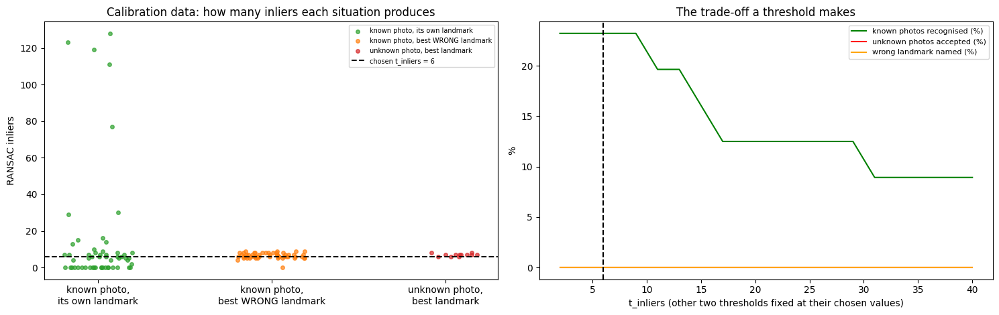

In [17]:
def evaluate_rule(thr, pos, neg):
    correct = wrong = 0
    for res, truth in pos:
        p = decide(res, thr)["predicted"]
        correct += p == truth
        wrong += (p is not None and p != truth)
    ua = sum(decide(res, thr)["predicted"] is not None for res, _ in neg)
    return dict(tpr=correct / max(len(pos), 1), wrong_rate=wrong / max(len(pos), 1), unknown_accept=ua / max(len(neg), 1))

def middle_of(top, cols):
    z = sum((top[c] - top[c].median()).abs() / (top[c].max() - top[c].min() + 1e-9) for c in cols)
    return top.loc[z.idxmin()]

cal = CONFIG["calibration"]
grid = []
for tg in cal["t_good_grid"]:
    for ti in cal["t_inliers_grid"]:
        for mg in cal["margin_grid"]:
            thr = dict(t_good=tg, t_inliers=ti, margin=mg)
            grid.append({**thr, **evaluate_rule(thr, POS, NEG)})
GRID = pd.DataFrame(grid)
chosen, level = None, None
for allowed in cal["allowed_unknown_accept"]:
    feas = GRID[(GRID["unknown_accept"] <= allowed) & (GRID["wrong_rate"] <= 0.02)]
    if len(feas):
        top = feas[feas["tpr"] == feas["tpr"].max()]
        chosen, level = middle_of(top, ["t_good", "t_inliers", "margin"]), allowed
        print(f"{len(feas)} threshold combinations accept at most {100 * allowed:.0f}% of the unknown photos and name a wrong landmark for at most 2% of the known ones;")
        print(f"{len(top)} of them recognise the most known photos ({100 * top['tpr'].max():.1f}%). Taking the one in the middle of that group.")
        break
if chosen is None:
    GRID["score"] = GRID["tpr"] - 2 * GRID["unknown_accept"] - 2 * GRID["wrong_rate"]
    chosen, level = GRID.loc[GRID["score"].idxmax()], None
    print("WARNING: no combination keeps the unknown photos out and stays accurate on the known ones.")
    print("Look at the contact sheets (a wrong photo may be in the database). Using the best compromise instead.")
THR = dict(t_good=int(chosen["t_good"]), t_inliers=int(chosen["t_inliers"]), margin=float(chosen["margin"]))
cal_perf = evaluate_rule(THR, POS, NEG)
EXTRAS.set("thresholds", THR); EXTRAS.set("calibration_performance", cal_perf)
print("\nChosen thresholds:", THR)
print(f"On the calibration data they recognise {100 * cal_perf['tpr']:.1f}% of known photos, name a wrong landmark for {100 * cal_perf['wrong_rate']:.1f}%, and accept {100 * cal_perf['unknown_accept']:.1f}% of unknown photos.")
simple = evaluate_rule(dict(t_good=0, t_inliers=10, margin=1.0), POS, NEG)
print(f"For comparison, a common rule of thumb (at least 10 inliers, nothing else) gives: recognised {100 * simple['tpr']:.1f}%, wrong landmark {100 * simple['wrong_rate']:.1f}%, unknown accepted {100 * simple['unknown_accept']:.1f}%.")

# how the evidence looks for known, wrong-landmark and unknown photos
pos_true, pos_wrong = [], []
for res, truth in POS:
    inl = {v["landmark"]: v["n_inliers"] for v in res["verified"]}
    pos_true.append(inl.get(truth, 0)); pos_wrong.append(max([n for lm, n in inl.items() if lm != truth], default=0))
neg_best = [max([v["n_inliers"] for v in res["verified"]], default=0) for res, _ in NEG]
fig, axes = plt.subplots(1, 2, figsize=(15, 4.8))
rs = np.random.RandomState(0)
for pos_x, vals, col, name in ((0, pos_true, "tab:green", "known photo,\nits own landmark"), (1, pos_wrong, "tab:orange", "known photo,\nbest WRONG landmark"), (2, neg_best, "tab:red", "unknown photo,\nbest landmark")):
    axes[0].scatter(pos_x + rs.uniform(-0.2, 0.2, len(vals)), vals, c=col, s=16, alpha=0.7, label=name.replace("\n", " "))
axes[0].axhline(THR["t_inliers"], color="k", linestyle="--", label=f"chosen t_inliers = {THR['t_inliers']}")
axes[0].set_xticks([0, 1, 2]); axes[0].set_xticklabels(["known photo,\nits own landmark", "known photo,\nbest WRONG landmark", "unknown photo,\nbest landmark"])
axes[0].set_ylabel("RANSAC inliers"); axes[0].set_title("Calibration data: how many inliers each situation produces"); axes[0].legend(fontsize=7)
curve = []
for ti in range(2, 41):
    m = evaluate_rule(dict(THR, t_inliers=ti), POS, NEG); curve.append((ti, m["tpr"], m["unknown_accept"], m["wrong_rate"]))
cv_ = np.array(curve)
axes[1].plot(cv_[:, 0], 100 * cv_[:, 1], "g-", label="known photos recognised (%)")
axes[1].plot(cv_[:, 0], 100 * cv_[:, 2], "r-", label="unknown photos accepted (%)")
axes[1].plot(cv_[:, 0], 100 * cv_[:, 3], "orange", label="wrong landmark named (%)")
axes[1].axvline(THR["t_inliers"], color="k", linestyle="--"); axes[1].set_xlabel("t_inliers (other two thresholds fixed at their chosen values)")
axes[1].set_ylabel("%"); axes[1].set_title("The trade-off a threshold makes"); axes[1].legend(fontsize=8)
plt.tight_layout(); save_fig("t8_threshold_calibration"); plt.show()

**What to look for.** Left: in this run the picture is not a clean separation. For most known photos the correct landmark collects almost nothing (0 to 10 inliers; 0 means the landmark was not among the three candidates that were checked, or had fewer than 8 reliable matches). Only a handful reach more than 70 inliers. The best wrong landmark (orange) and the best landmark for an unknown photo (red) both sit at about 4 to 9 inliers, so the chosen line (6) lies inside that noise band: the unknown photos are kept out by the margin check, not by the inlier count. Right: raising `t_inliers` cannot reduce wrong answers (they are already 0%) but it quickly loses known photos: 23.2% are recognised at 6, 12.5% from 17 to 29, 8.9% above 30. A threshold cannot repair a weak signal; it only moves the system along the trade-off.

## 9. Task 6: Performance evaluation

**In plain words.** Now the test. Everything here uses photos that were **not** used to choose the thresholds:
- **Held-out photos** of the known landmarks (the visitor photos the system has never seen), and
- **Unknown test places** (not in the database): the system should say "rejected" for them.

We report how many known photos are recognised, how many are wrongly rejected, how many get the wrong name, and how many unknown photos are wrongly accepted. Then we compare three decision rules to show why the brief warns against "largest count wins".

[test_known] already done (28 photos)
  [test_unknown] 10/12 photos (29s)
  [test_unknown] 12/12 photos (35s)
Known landmarks, held-out photos (28): recognised correctly 5 (17.9%), wrong landmark named 0, wrongly rejected 23
Unknown places (12 photos): correctly rejected 11 (91.7%), wrongly accepted 1
Overall decisions correct: 16 of 40 (40.0%)   |   mean time per query 2.88 s

Per landmark (held-out photos):
                       photos  recognised  wrong  rejected  median_inliers
landmark                                                                  
Angkor Wat                  4           0      0         4               6
Big Ben                     4           1      0         3               9
Burj Khalifa                4           0      0         4               6
Hagia Sophia                4           1      0         3               5
Leaning Tower of Pisa       4           2      0         2              11
Petra Treasury              4           1      0         3    

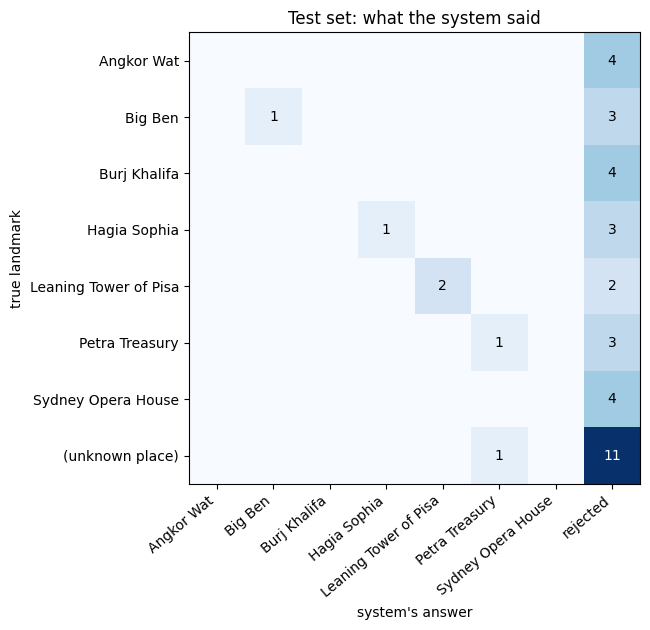

In [18]:
run_batch(IMAGES[IMAGES["role"] == "heldout"], "test_known")
run_batch(IMAGES[IMAGES["role"] == "unk_test"], "test_unknown")
test_rows = []
for r in IMAGES[IMAGES["role"].isin(["heldout", "unk_test"])].itertuples():
    res = QRES.get(f"{'test_known' if r.role == 'heldout' else 'test_unknown'}/{r.image_id}")
    d = decide(res, THR); cand = res["verified"][0] if res["verified"] else None
    test_rows.append(dict(image_id=r.image_id, true=r.landmark if r.role == "heldout" else "(unknown place)", query=r.file, known=r.role == "heldout", predicted=d["predicted"],
                          candidate=d["candidate"], count_winner=d["count_winner"], keypoints=res["n_kp"], reliable_matches=cand["n_good"] if cand else 0,
                          inliers=cand["n_inliers"] if cand else 0, decision=d["decision"], time_s=round(res["t_total"], 2), reason=d["reason"]))
TEST = pd.DataFrame(test_rows)
K, U = TEST[TEST["known"]], TEST[~TEST["known"]]
n_ok = int((K["predicted"] == K["true"]).sum()); n_wrong = int((K["predicted"].notna() & (K["predicted"] != K["true"])).sum()); n_rej = int(K["predicted"].isna().sum())
u_rej = int(U["predicted"].isna().sum()); u_acc = len(U) - u_rej
print(f"Known landmarks, held-out photos ({len(K)}): recognised correctly {n_ok} ({100 * n_ok / len(K):.1f}%), wrong landmark named {n_wrong}, wrongly rejected {n_rej}")
print(f"Unknown places ({len(U)} photos): correctly rejected {u_rej} ({100 * u_rej / max(len(U), 1):.1f}%), wrongly accepted {u_acc}")
print(f"Overall decisions correct: {n_ok + u_rej} of {len(TEST)} ({100 * (n_ok + u_rej) / len(TEST):.1f}%)   |   mean time per query {TEST['time_s'].mean():.2f} s")
SUMMARY = dict(known_queries=len(K), known_correct=n_ok, known_wrong=n_wrong, known_rejected=n_rej, unknown_queries=len(U), unknown_rejected=u_rej, unknown_accepted=u_acc,
               overall_correct=n_ok + u_rej, overall=len(TEST), mean_time_s=float(TEST["time_s"].mean()))
EXTRAS.set("test_summary", SUMMARY)

per_lm = pd.DataFrame([dict(landmark=lm, photos=len(g), recognised=int((g["predicted"] == g["true"]).sum()),
                            wrong=int((g["predicted"].notna() & (g["predicted"] != g["true"])).sum()),
                            rejected=int(g["predicted"].isna().sum()), median_inliers=int(g["inliers"].median()))
                       for lm, g in K.groupby("true")]).set_index("landmark")
print("\nPer landmark (held-out photos):")
print(per_lm.to_string())

# confusion matrix: rows = truth, columns = what the system said
rows_lbl = KNOWN + ["(unknown place)"]; cols_lbl = KNOWN + ["rejected"]
CM = np.zeros((len(rows_lbl), len(cols_lbl)), int)
for t, p in zip(TEST["true"], TEST["predicted"]):
    CM[rows_lbl.index(t), cols_lbl.index(p) if p is not None and p == p else len(cols_lbl) - 1] += 1
fig, ax = plt.subplots(figsize=(9.5, 6.4))
ax.imshow(CM, cmap="Blues")
ax.set_xticks(range(len(cols_lbl))); ax.set_xticklabels(cols_lbl, rotation=40, ha="right"); ax.set_yticks(range(len(rows_lbl))); ax.set_yticklabels(rows_lbl)
for (i, j), v in np.ndenumerate(CM):
    if v: ax.text(j, i, v, ha="center", va="center", color="white" if v > CM.max() / 2 else "black")
ax.set_xlabel("system's answer"); ax.set_ylabel("true landmark"); ax.set_title("Test set: what the system said")
plt.tight_layout(); save_fig("t9_confusion_matrix"); plt.show()
TEST.to_csv(os.path.join(CKPT_DIR, "test_results.csv"), index=False)

                                         known_recognised_pct  wrong_name_pct  known_rejected_pct  unknown_accepted_pct
A: largest match count wins                              42.9            57.1                 0.0                 100.0
B: reliable matches >= 84                                 3.6             3.6                92.9                   0.0
C: our rule (matches + RANSAC + margin)                  17.9             0.0                82.1                   8.3


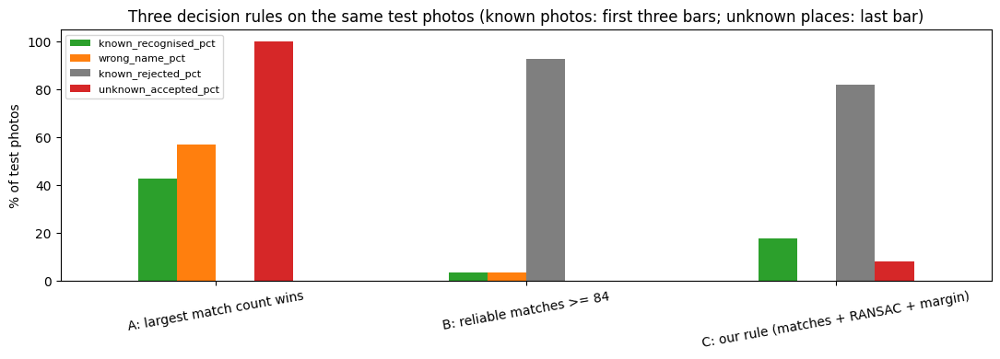

In [19]:
# Why not "largest count wins"? Three decision rules on the same test photos.
def rule_largest_count(res):
    return res["ranking"][0]["landmark"] if res["ranking"] else None

def rule_count_threshold(res, t):
    return res["ranking"][0]["landmark"] if res["ranking"] and res["ranking"][0]["n_good"] >= t else None

cal_B = []
for t in range(5, 120):
    ok = wrong = 0
    for res, truth in POS:
        p = rule_count_threshold(res, t); ok += p == truth; wrong += (p is not None and p != truth)
    ua = sum(rule_count_threshold(res, t) is not None for res, _ in NEG)
    cal_B.append(dict(t=t, tpr=ok / len(POS), wrong_rate=wrong / len(POS), unknown_accept=ua / max(len(NEG), 1)))
CB = pd.DataFrame(cal_B)
t_B = None
for allowed in cal["allowed_unknown_accept"]:
    feas = CB[(CB["unknown_accept"] <= allowed) & (CB["wrong_rate"] <= 0.02)]
    if len(feas):
        t_B = int(middle_of(feas[feas["tpr"] == feas["tpr"].max()], ["t"])["t"]); break
t_B = t_B if t_B is not None else int(CB["t"].max())

def score_rule(fn):
    k_ok = k_wrong = k_rej = 0
    for r in K.itertuples():
        p = fn(QRES.get(f"test_known/{r.image_id}"))
        k_ok += p == r.true; k_wrong += (p is not None and p != r.true); k_rej += p is None
    u_acc_ = 0
    for r in U.itertuples():
        u_acc_ += fn(QRES.get(f"test_unknown/{r.image_id}")) is not None
    return dict(known_recognised_pct=100 * k_ok / len(K), wrong_name_pct=100 * k_wrong / len(K), known_rejected_pct=100 * k_rej / len(K), unknown_accepted_pct=100 * u_acc_ / max(len(U), 1))

rules = {"A: largest match count wins": score_rule(rule_largest_count),
         f"B: reliable matches >= {t_B}": score_rule(lambda res: rule_count_threshold(res, t_B)),
         "C: our rule (matches + RANSAC + margin)": score_rule(lambda res: decide(res, THR)["predicted"])}
RULES = pd.DataFrame(rules).T.round(1)
print(RULES.to_string())
EXTRAS.set("rule_comparison", RULES.to_dict("index"))
fig, ax = plt.subplots(figsize=(11, 4))
RULES[["known_recognised_pct", "wrong_name_pct", "known_rejected_pct", "unknown_accepted_pct"]].plot(kind="bar", ax=ax, rot=10, color=["tab:green", "tab:orange", "tab:gray", "tab:red"])
ax.set_ylabel("% of test photos"); ax.set_title("Three decision rules on the same test photos (known photos: first three bars; unknown places: last bar)"); ax.legend(fontsize=8)
plt.tight_layout(); save_fig("t9_decision_rule_comparison"); plt.show()

**What to look for.** Rule A always names a landmark, so it can never reject an unknown place: the red bar is 100%. Rule B adds a match-count threshold and catches the unknown places, but counting alone also lets through coincidences and cannot tell two similar candidates apart. Rule C adds the geometric check and the margin. The point is not that C wins by a lot on this small test; it is that C's decisions can be *explained* (enough matches, enough of them geometrically consistent, clearly ahead), and that it is the only rule that has a reason for every rejection. In this run: rule A recognises 42.9% of the held-out photos but names the wrong landmark for 57.1% and accepts all 12 unknown photos; rule B (at least 84 reliable matches) recognises 3.6%; rule C recognises 17.9%, names no wrong landmark and accepts 1 of 12 unknown photos.

Task 6: one test per condition and landmark (correct = the right landmark, or a rejection for the unknown place)

                               landmark           condition                        query             predicted  keypoints  reliable_matches  ransac_inliers   decision correct  time_s
                             Angkor Wat            original            angkor_wat_09.jpg            (rejected)       1500                53               7   REJECTED      no    3.26
                             Angkor Wat      rotated 45 deg            angkor_wat_09.jpg            (rejected)       1500                49               7   REJECTED      no    3.35
                             Angkor Wat         resized 50%            angkor_wat_09.jpg          Burj Khalifa       1500                44               9 RECOGNIZED      no    3.09
                             Angkor Wat     brightness x0.4            angkor_wat_09.jpg            (rejected)       1275                42               

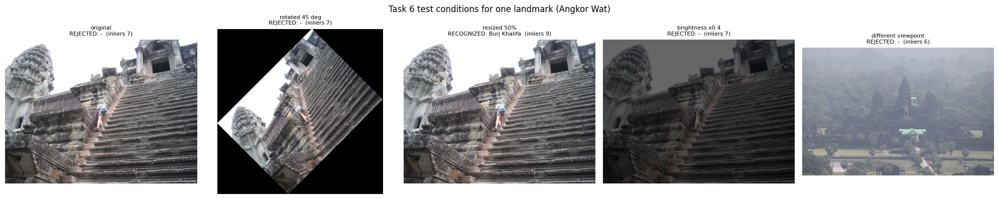

In [20]:
# ---- Task 6: the six conditions of the brief ----
COND = CONFIG["conditions"]

def rotate_bound(img, angle):
    h, w = img.shape[:2]; c = (w / 2, h / 2)
    M = cv2.getRotationMatrix2D(c, angle, 1.0)
    cos, sin = abs(M[0, 0]), abs(M[0, 1])
    nw, nh = int(h * sin + w * cos), int(h * cos + w * sin)
    M[0, 2] += nw / 2 - c[0]; M[1, 2] += nh / 2 - c[1]
    return cv2.warpAffine(img, M, (nw, nh), flags=cv2.INTER_LINEAR, borderValue=(0, 0, 0))

def resize_by(img, s):
    return cv2.resize(img, None, fx=s, fy=s, interpolation=cv2.INTER_AREA if s < 1 else cv2.INTER_CUBIC)

def darken(img, f):
    return cv2.convertScaleAbs(img, alpha=f, beta=0)

def transform(img, family, value):
    return {"rotation": rotate_bound, "scale": resize_by, "brightness": darken}[family](img, value)

def run_variant(key, bgr):
    if QRES.has(key):
        return QRES.get(key)
    res = analyse_query(extract_features(bgr)); QRES.set(key, res)
    return res

rows6, examples = [], {}
for lm in KNOWN:
    held = IMAGES[(IMAGES["role"] == "heldout") & (IMAGES["landmark"] == lm)].reset_index(drop=True)
    if len(held) == 0:
        continue
    orig = held.iloc[0]; obgr = load_bgr(orig.path)
    # "different viewpoint": the other held-out photo that shares the FEWEST reliable matches with the original (a proxy for a larger viewpoint change)
    others = held.iloc[1:]
    view = None
    if len(others):
        shared = [len(good_matches(FEATS[orig.image_id]["desc"], FEATS[o.image_id]["desc"])[0]) for o in others.itertuples()]
        view = others.iloc[int(np.argmin(shared))]
    conds = [("original", obgr, f"test_known/{orig.image_id}", orig.file)]
    conds += [("rotated %d deg" % COND["rotation_deg"], rotate_bound(obgr, COND["rotation_deg"]), f"task6/{lm}/rotated", orig.file),
              ("resized %d%%" % round(100 * COND["scale"]), resize_by(obgr, COND["scale"]), f"task6/{lm}/resized", orig.file),
              ("brightness x%.1f" % COND["brightness"], darken(obgr, COND["brightness"]), f"task6/{lm}/dark", orig.file)]
    if view is not None:
        conds.append(("different viewpoint", load_bgr(view.path), f"test_known/{view.image_id}", view.file))
    for name, img, key, fname in conds:
        res = QRES.get(key) if key.startswith("test_known/") else run_variant(key, img)
        d = decide(res, THR); cand = res["verified"][0] if res["verified"] else None
        rows6.append(dict(landmark=lm, condition=name, query=fname, predicted=d["predicted"] or "(rejected)", keypoints=res["n_kp"],
                          reliable_matches=cand["n_good"] if cand else 0, ransac_inliers=cand["n_inliers"] if cand else 0,
                          decision=d["decision"], correct="yes" if d["predicted"] == lm else "no", time_s=round(res["t_total"], 2)))
        if lm == KNOWN[0]:
            examples[name] = (img, d, cand)
for u in IMAGES[IMAGES["role"] == "unk_test"].groupby("landmark").head(1).itertuples():
    res = QRES.get(f"test_unknown/{u.image_id}"); d = decide(res, THR); cand = res["verified"][0] if res["verified"] else None
    rows6.append(dict(landmark=f"{u.landmark} (not in database)", condition="unknown landmark", query=u.file, predicted=d["predicted"] or "(rejected)", keypoints=res["n_kp"],
                      reliable_matches=cand["n_good"] if cand else 0, ransac_inliers=cand["n_inliers"] if cand else 0, decision=d["decision"],
                      correct="yes" if d["predicted"] is None else "no", time_s=round(res["t_total"], 2)))
QRES.flush()
T6 = pd.DataFrame(rows6)
T6.to_csv(os.path.join(CKPT_DIR, "task6_results.csv"), index=False)
print("Task 6: one test per condition and landmark (correct = the right landmark, or a rejection for the unknown place)\n")
print(T6.to_string(index=False))
by_cond = T6.groupby("condition").agg(tests=("correct", "size"), correct=("correct", lambda s: int((s == "yes").sum())), mean_inliers=("ransac_inliers", "mean"), mean_time_s=("time_s", "mean")).round(2)
print("\nSummary by condition:"); print(by_cond.to_string())

first_lm = KNOWN[0]
fig, axes = plt.subplots(1, len(examples), figsize=(4 * len(examples), 4))
for ax, (name, (img, d, cand)) in zip(np.atleast_1d(axes), examples.items()):
    show_bgr(ax, img, f"{name}\n{d['decision']}: {d['predicted'] or '-'}  (inliers {cand['n_inliers'] if cand else 0})", fontsize=8)
plt.suptitle(f"Task 6 test conditions for one landmark ({first_lm})"); plt.tight_layout(); save_fig("t6_condition_examples"); plt.show()

  sweeps: 10 new runs (33s)
  sweeps: 20 new runs (66s)
  sweeps: 30 new runs (100s)
  sweeps: 40 new runs (132s)
  sweeps: 50 new runs (165s)
  sweeps: 60 new runs (185s)
  sweeps: 70 new runs (194s)
  sweeps: 80 new runs (215s)
  sweeps: 90 new runs (243s)
  sweeps: 100 new runs (270s)
  sweeps: 110 new runs (275s)
  sweeps: 120 new runs (296s)
  sweeps: 130 new runs (325s)
  sweeps: 140 new runs (357s)


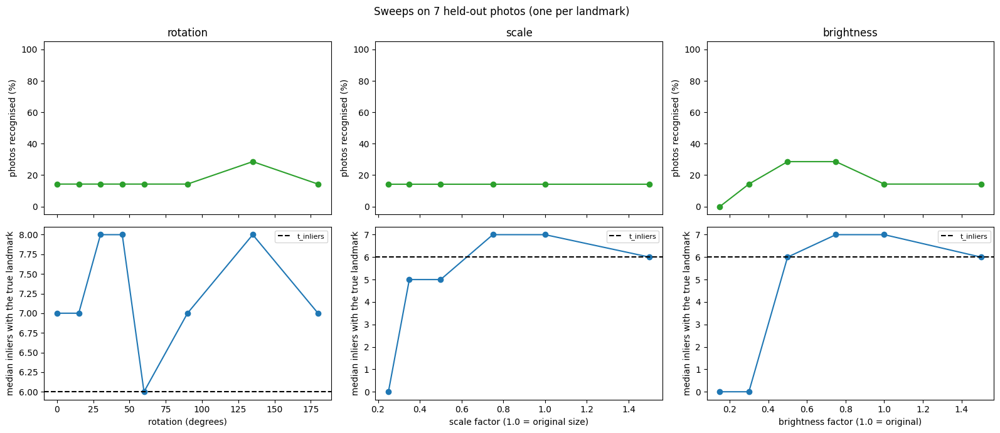

In [21]:
# ---- sweeps: where does SIFT's invariance stop working? ----
SW = CONFIG["sweeps"]
base = []
for lm in KNOWN:
    held_lm = IMAGES[(IMAGES["role"] == "heldout") & (IMAGES["landmark"] == lm)]
    if len(held_lm):
        base.append(held_lm.iloc[0])
base_bgr = {b.landmark: load_bgr(b.path) for b in base}
t0 = time.time(); done = 0
for family, values in SW.items():
    for v in values:
        for b in base:
            key = f"sweep/{family}/{v}/{b.landmark}"
            if QRES.has(key):
                continue
            QRES.put(key, analyse_query(extract_features(transform(base_bgr[b.landmark], family, v)))); done += 1
            if done % 10 == 0:
                QRES.flush(); print(f"  sweeps: {done} new runs ({time.time() - t0:.0f}s)", flush=True)
QRES.flush()
sw_rows = []
for family, values in SW.items():
    for v in values:
        for b in base:
            res = QRES.get(f"sweep/{family}/{v}/{b.landmark}"); d = decide(res, THR)
            own = next((x["n_inliers"] for x in res["verified"] if x["landmark"] == b.landmark), 0)
            sw_rows.append(dict(family=family, value=v, landmark=b.landmark, correct=d["predicted"] == b.landmark, own_inliers=own))
SWDF = pd.DataFrame(sw_rows)
fig, axes = plt.subplots(2, 3, figsize=(16, 7), sharex="col")
labels = {"rotation": "rotation (degrees)", "scale": "scale factor (1.0 = original size)", "brightness": "brightness factor (1.0 = original)"}
for c, family in enumerate(SW):
    g = SWDF[SWDF["family"] == family].groupby("value").agg(success=("correct", "mean"), inl=("own_inliers", "median"))
    axes[0, c].plot(g.index, 100 * g["success"], "o-", color="tab:green"); axes[0, c].set_ylim(-5, 105); axes[0, c].set_ylabel("photos recognised (%)")
    axes[1, c].plot(g.index, g["inl"], "o-", color="tab:blue"); axes[1, c].axhline(THR["t_inliers"], color="k", linestyle="--", label="t_inliers")
    axes[1, c].set_xlabel(labels[family]); axes[1, c].set_ylabel("median inliers with the true landmark"); axes[1, c].legend(fontsize=8)
    axes[0, c].set_title(family)
plt.suptitle(f"Sweeps on {len(base)} held-out photos (one per landmark)"); plt.tight_layout(); save_fig("t6_sweeps"); plt.show()
SWDF.to_csv(os.path.join(CKPT_DIR, "sweep_results.csv"), index=False)

**What to look for.** In this run only one of the seven base photos (Hagia Sophia) is recognised at the original orientation and size, so the success curves sit at 1 of 7 (14%) almost everywhere, and the median inliers sit at the noise level (about 5 to 8). These sweeps therefore say little about SIFT's invariance: if most base photos already fail at the starting point, rotating or resizing them cannot make them fail further. The clearest evidence of invariance is the Hagia Sophia row of the Task 6 table: 175 inliers for the original, 172 rotated by 45 degrees, 92 at half size and 93 at brightness x0.4. A cleaner invariance test would match each photo against its own transformed copy; that was not done here.

Time per query over the test photos (milliseconds):
 stage  mean_ms  median_ms
  sift    161.3      165.0
 match   2627.2     2868.3
ransac     92.3       81.7
 total   2880.8     3136.1


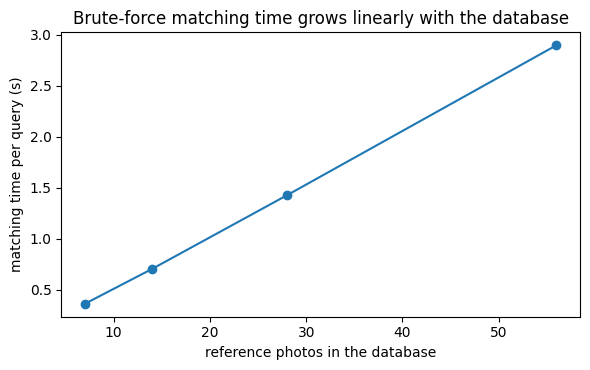

Reference photos: [7, 14, 28, 56] -> matching seconds per query: [0.36, 0.7, 1.43, 2.9]


In [22]:
# ---- how long does it take, and how does matching time grow with the size of the database? ----
tm = pd.DataFrame([dict(stage=s, mean_ms=1000 * np.mean([QRES.get(k)[f"t_{s}"] for k in QRES.data if k.startswith("test_")]),
                        median_ms=1000 * np.median([QRES.get(k)[f"t_{s}"] for k in QRES.data if k.startswith("test_")]))
                   for s in ("sift", "match", "ransac", "total")]).round(1)
print("Time per query over the test photos (milliseconds):"); print(tm.to_string(index=False))

sizes_, times_ = [], []
probe = [FEATS[IMAGES[(IMAGES["role"] == "heldout") & (IMAGES["landmark"] == lm)].iloc[0]["image_id"]] for lm in KNOWN[:5]]
for per in (1, 2, 4, max(len([r for r in REF_IDS if LM_OF[r] == KNOWN[0]]), 4)):
    subset = [rid for lm in KNOWN for rid in [r for r in REF_IDS if LM_OF[r] == lm][:per]]
    t0 = time.perf_counter()
    for q in probe:
        for rid in subset:
            good_matches(q["desc"], FEATS[rid]["desc"])
    sizes_.append(len(subset)); times_.append((time.perf_counter() - t0) / len(probe))
fig, ax = plt.subplots(figsize=(6, 3.8))
ax.plot(sizes_, times_, "o-"); ax.set_xlabel("reference photos in the database"); ax.set_ylabel("matching time per query (s)")
ax.set_title("Brute-force matching time grows linearly with the database")
plt.tight_layout(); save_fig("t6_matching_time_vs_database_size"); plt.show()
print("Reference photos:", sizes_, "-> matching seconds per query:", [round(t, 2) for t in times_])

24 test photos went wrong. Showing 4 case(s) (errors first, then the weakest correct recognitions).


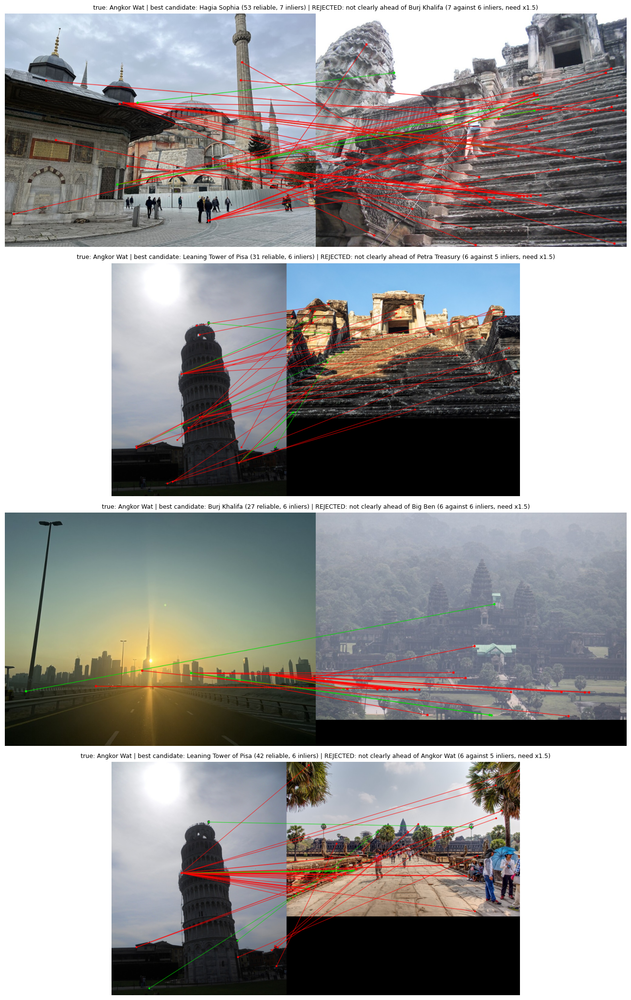

In [23]:
# ---- failure analysis: the cases that went wrong, and the weakest successes ----
bad = TEST[(TEST["known"] & (TEST["predicted"] != TEST["true"])) | ((~TEST["known"]) & TEST["predicted"].notna())]
weak = TEST[TEST["known"] & (TEST["predicted"] == TEST["true"])].sort_values("inliers").head(max(0, 4 - len(bad)))
show = pd.concat([bad.head(4), weak]).head(4)
print(f"{len(bad)} test photos went wrong. Showing {len(show)} case(s) (errors first, then the weakest correct recognitions).")
if len(show):
    fig, axes = plt.subplots(len(show), 1, figsize=(14, 5.2 * len(show)), squeeze=False)
    for ax, r in zip(axes.ravel(), show.itertuples()):
        iid = r.image_id
        res, per_ref = analyse_query(FEATS[iid], keep_matches=True)
        cand = res["verified"][0]; qi_, ri_ = per_ref[cand["ref"]]
        H_, m_ = ransac_verify(FEATS[iid]["pt"], FEATS[cand["ref"]]["pt"], qi_, ri_)
        show_bgr(ax, draw_match_lines(load_bgr(PATH_OF[cand["ref"]]), load_bgr(PATH_OF[iid]), FEATS[cand["ref"]]["pt"], FEATS[iid]["pt"], ri_, qi_, m_),
                 f"true: {r.true} | best candidate: {cand['landmark']} ({cand['n_good']} reliable, {cand['n_inliers']} inliers) | {r.decision}: {r.reason}", fontsize=9)
    plt.tight_layout(); save_fig("t9_failure_and_weak_cases"); plt.show()

**What to look for.** For every case ask the three questions a viva examiner would: *Which matches survived the ratio test? Do they sit on the same object? Why did the rule decide as it did?* Typical reasons for trouble: a very different viewpoint (the flat-surface assumption of the homography breaks), a plain facade with few distinctive keypoints, strong shadows or night lighting, and repeated patterns (columns, windows) that create look-alike matches. The printed reason is the exact check that failed. In this run the four cases shown are the first four errors in file order, all Angkor Wat photos. In each, the best candidate is an unrelated landmark, almost every match line is red (a chance match), and the 6 to 7 'inliers' are the noise floor of this setup.

## 10. The application: what a visitor sees

**In plain words.** `recognize_landmark(photo)` is the application for the tourism information centre. A visitor's photo goes in; out comes a printed result block and a picture with the seven things the brief asks for: the **query photo**, the **detected keypoints**, the **matched features** between query and best reference, the **predicted landmark name**, the **number of reliable matches**, the **localized region** (only when the geometry is trustworthy) and a **message** saying recognised or rejected.

A. a held-out photo of a known landmark

LANDMARK RECOGNITION RESULT
Query photo: /content/lab06_data/queries/known/Angkor Wat/angkor_wat_09.jpg
Keypoints found in the query: 1500
Most likely landmark: Hagia Sophia (best reference photo: hagia_sophia_08.jpg)
Reliable matches (ratio test): 53
RANSAC inliers: 7 (13% of the reliable matches)
Runner-up: Burj Khalifa with 6 inliers
Localization: outline NOT drawn: the outline is twisted (not convex)
Decision: REJECTED (not clearly ahead of Burj Khalifa (7 against 6 inliers, need x1.5))
Processing time: 3.29 s (SIFT 0.30, matching 2.83, RANSAC 0.17)


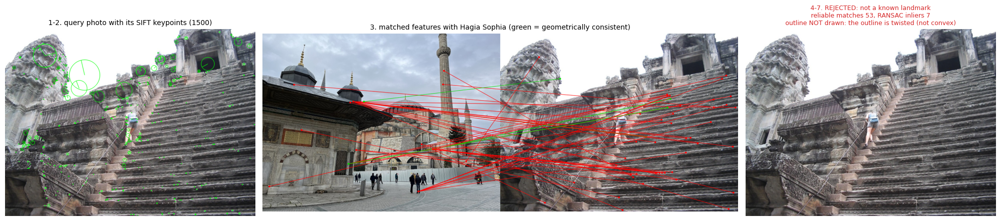

In [24]:
def recognize_landmark(source, thr=None, show=True, exclude_id=None, save_as=None):
    '''source: a file path or a BGR image array. Returns the result dictionary.'''
    thr = THR if thr is None else thr
    qbgr, qfeat = process_query(source)
    res, per_ref = analyse_query(qfeat, exclude_id=exclude_id, keep_matches=True)
    d = decide(res, thr); cand = res["verified"][0] if res["verified"] else None
    runner = res["verified"][1] if len(res["verified"]) > 1 else None
    poly_msg = "no candidate"
    if cand is not None:
        poly_msg = ("outline drawn (outline checks passed)" if (cand["poly_ok"] and d["decision"] == "RECOGNIZED") else
                    ("outline NOT drawn: " + (cand["poly_reason"] if not cand["poly_ok"] else "the photo was not recognised")))
    print("LANDMARK RECOGNITION RESULT")
    print(f"Query photo: {source if isinstance(source, str) else '(image array)'}")
    print(f"Keypoints found in the query: {res['n_kp']}")
    if cand is not None:
        print(f"Most likely landmark: {cand['landmark']} (best reference photo: {cand['ref'].split('/')[-1]}.jpg)")
        print(f"Reliable matches (ratio test): {cand['n_good']}")
        print(f"RANSAC inliers: {cand['n_inliers']} ({100 * cand['inlier_ratio']:.0f}% of the reliable matches)")
        if runner is not None:
            print(f"Runner-up: {runner['landmark']} with {runner['n_inliers']} inliers")
    print(f"Localization: {poly_msg}")
    print(f"Decision: {d['decision']}" + (f" as {d['predicted']}" if d["predicted"] else f" ({d['reason']})"))
    print(f"Processing time: {res['t_total']:.2f} s (SIFT {res['t_sift']:.2f}, matching {res['t_match']:.2f}, RANSAC {res['t_ransac']:.2f})")
    if show and cand is not None:
        qi, ri = per_ref[cand["ref"]]
        H, mask = ransac_verify(qfeat["pt"], FEATS[cand["ref"]]["pt"], qi, ri)
        rbgr = load_bgr(PATH_OF[cand["ref"]])
        fig, axes = plt.subplots(1, 3, figsize=(20, 5.4), gridspec_kw={"width_ratios": [1, 1.9, 1]})
        show_bgr(axes[0], draw_keypoints(qbgr, qfeat, top=400), f"1-2. query photo with its SIFT keypoints ({res['n_kp']})", fontsize=10)
        show_bgr(axes[1], draw_match_lines(rbgr, qbgr, FEATS[cand["ref"]]["pt"], qfeat["pt"], ri, qi, mask),
                 f"3. matched features with {cand['landmark']} (green = geometrically consistent)", fontsize=10)
        out = qbgr.copy()
        if d["decision"] == "RECOGNIZED" and cand["poly_ok"] and cand["poly"] is not None:
            cv2.polylines(out, [np.round(np.array(cand["poly"])).astype(np.int32).reshape(-1, 1, 2)], True, (0, 0, 255), 4, cv2.LINE_AA)
        axes[2].imshow(cv2.cvtColor(out, cv2.COLOR_BGR2RGB)); _clean_axis(axes[2])
        colour = "tab:green" if d["decision"] == "RECOGNIZED" else "tab:red"
        head = f"RECOGNIZED: {d['predicted']}" if d["predicted"] else "REJECTED: not a known landmark"
        axes[2].set_title(f"4-7. {head}\nreliable matches {cand['n_good']}, RANSAC inliers {cand['n_inliers']}\n{poly_msg}", fontsize=9, color=colour)
        plt.tight_layout()
        if save_as:
            save_fig(save_as, fig)
        plt.show()
    return dict(result=res, decision=d)

demo_lm = KNOWN[0]
demo_photo = IMAGES[(IMAGES["role"] == "heldout") & (IMAGES["landmark"] == demo_lm)].iloc[0]
print("=" * 70, "\nA. a held-out photo of a known landmark\n")
_ = recognize_landmark(demo_photo.path, save_as="t10_application_known")

B. the same photo rotated by 45 degrees

LANDMARK RECOGNITION RESULT
Query photo: (image array)
Keypoints found in the query: 1501
Most likely landmark: Leaning Tower of Pisa (best reference photo: leaning_tower_of_pisa_07.jpg)
Reliable matches (ratio test): 77
RANSAC inliers: 6 (8% of the reliable matches)
Runner-up: Burj Khalifa with 6 inliers
Localization: outline NOT drawn: the outline is twisted (not convex)
Decision: REJECTED (not clearly ahead of Burj Khalifa (6 against 6 inliers, need x1.5))
Processing time: 3.42 s (SIFT 0.28, matching 2.83, RANSAC 0.31)


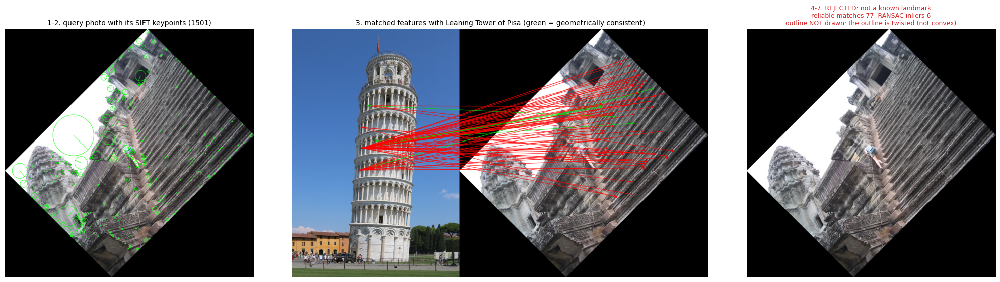

C. the same photo with brightness x0.4

LANDMARK RECOGNITION RESULT
Query photo: (image array)
Keypoints found in the query: 1275
Most likely landmark: Hagia Sophia (best reference photo: hagia_sophia_08.jpg)
Reliable matches (ratio test): 42
RANSAC inliers: 7 (17% of the reliable matches)
Runner-up: Burj Khalifa with 6 inliers
Localization: outline NOT drawn: the outline is twisted (not convex)
Decision: REJECTED (not clearly ahead of Burj Khalifa (7 against 6 inliers, need x1.5))
Processing time: 2.91 s (SIFT 0.19, matching 2.55, RANSAC 0.16)


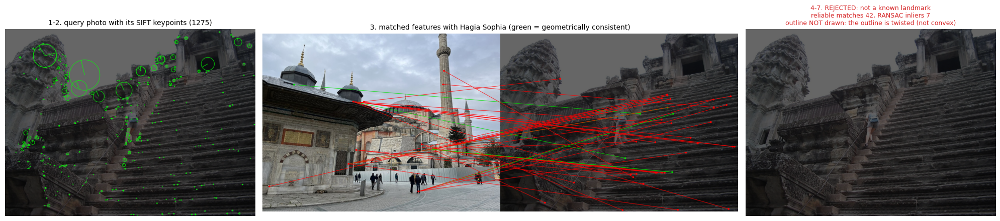

D. a photo of a place that is NOT in the database

LANDMARK RECOGNITION RESULT
Query photo: /content/lab06_data/queries/unknown_test/Eiffel Tower/eiffel_tower_01.jpg
Keypoints found in the query: 1500
Most likely landmark: Burj Khalifa (best reference photo: burj_khalifa_05.jpg)
Reliable matches (ratio test): 28
RANSAC inliers: 8 (29% of the reliable matches)
Runner-up: Hagia Sophia with 7 inliers
Localization: outline NOT drawn: the outline is twisted (not convex)
Decision: REJECTED (not clearly ahead of Hagia Sophia (8 against 7 inliers, need x1.5))
Processing time: 3.14 s (SIFT 0.20, matching 2.90, RANSAC 0.03)


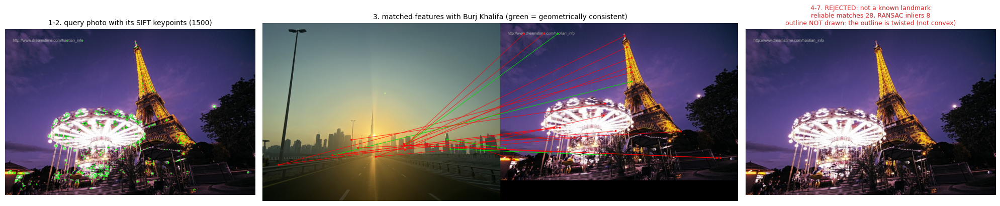

In [25]:
print("=" * 70, "\nB. the same photo rotated by 45 degrees\n")
_ = recognize_landmark(rotate_bound(load_bgr(demo_photo.path), 45), save_as="t10_application_rotated")
print("=" * 70, "\nC. the same photo with brightness x0.4\n")
_ = recognize_landmark(darken(load_bgr(demo_photo.path), 0.4))
print("=" * 70, "\nD. a photo of a place that is NOT in the database\n")
unk_photo = IMAGES[IMAGES["role"] == "unk_test"].iloc[0]
_ = recognize_landmark(unk_photo.path, save_as="t10_application_unknown")

**What to look for.** All four demos are REJECTED in this run, because the known-landmark photo used here (the first held-out Angkor Wat photo, a staircase) is not recognised even before it is rotated or darkened. A: the best candidate (Hagia Sophia) has only 7 inliers against 6 for Burj Khalifa, so the margin check fails, and the outline is not drawn because the projected outline is twisted. B and C: the same photo rotated by 45 degrees, or darkened, gives the same kind of result. D: the Eiffel Tower night photo (a place that is not in the database) is rejected, as intended. A successful recognition with a drawn outline is shown in Section 7 (Hagia Sophia, 175 inliers). To see a successful application output, call `recognize_landmark` on the Hagia Sophia held-out photo `hagia_sophia_09.jpg`.

## 11. Summary and saved files

**Ideas to remember (and to be able to explain)**
1. SIFT turns a photo into keypoints that are found at many scales (scale invariance) and described relative to their own direction (rotation invariance); each keypoint has a 128-number descriptor.
2. Matching = nearest descriptor by Euclidean distance (brute force). The **ratio test** keeps a match only if the best is clearly better than the second best.
3. A landmark's score is the count of reliable matches of its best reference photo, but the **largest count alone is not a decision**.
4. **RANSAC** fits a homography from random 4-match samples and counts how many matches agree (inliers). Chance matches rarely agree, so inliers are strong evidence.
5. The **decision thresholds are measured** on calibration data (known photos by leave-one-out, plus unknown places), never on the test photos.
6. The projected **polygon** shows where the reference photo lands in the query; it is only drawn when its shape is believable.
7. SIFT handles rotation and scale well, illumination partly, and big viewpoint changes badly; brute force matching gets slower in proportion to the database size.

**Glossary in plain words**

| Term | Meaning |
|---|---|
| Keypoint | A small spot in the photo (a corner, a blob) that is easy to find again. It has a position, a size (scale) and a direction. |
| Descriptor | The 128 numbers that describe the neighbourhood of one keypoint. Close descriptors mean similar-looking spots. |
| Scale space, octave | The photo blurred more and more (and shrunk by half after each octave), so spots of every size can be found. |
| DoG | Difference of Gaussians: two neighbouring blur levels subtracted. It highlights blobs of the matching size. |
| Gradient | The direction and strength of the brightness change at a pixel. |
| Brute-force matcher | Compares one descriptor with every other descriptor and returns the closest ones. |
| k-NN with k = 2 | Keep the two closest descriptors instead of one. |
| Ratio test | Keep a match only if the closest descriptor is clearly closer than the second closest (here: below 0.75 times). |
| Reliable match | A match that passed the ratio test. |
| Homography | A 3 x 3 matrix that maps points of one photo of a flat surface to the other photo (shift, rotation, scale, perspective). |
| RANSAC | Repeat: guess a homography from 4 random matches, count how many matches agree; keep the best guess. |
| Inlier / outlier | A match that agrees / does not agree with the best homography (within 5 pixels). |
| Threshold | A limit in the decision rule (for example "at least 15 inliers"). Here it is measured on calibration data. |
| Calibration set | Photos with known answers (known photos by leave-one-out, plus unknown places) used only to choose thresholds. |
| Leave-one-out | Using a database photo as a query after removing that photo from the database. |
| False accept / false reject | Naming a landmark for a photo that should be rejected or named differently / rejecting a photo that should be recognised. |
| Invariance | Not changing when something changes: SIFT descriptors stay (almost) the same when the photo is rotated or rescaled. |

In [26]:
APP_CONFIG = dict(run_id=RUN_SIG, database_id=DB_SIG, landmarks=KNOWN, sift=CONFIG["sift"], ratio=CONFIG["ratio"], ransac=CONFIG["ransac"],
                  verify_top_landmarks=CONFIG["verify_top_landmarks"], polygon=CONFIG["polygon"], thresholds=THR,
                  database_folder="database", opencv_version=cv2.__version__)
_atomic_write(os.path.join(CKPT_DIR, "landmark_config.json"), json.dumps(APP_CONFIG, indent=1, default=_json_default))
final = dict(run_id=RUN_SIG, photos=len(IMAGES), landmarks=KNOWN, thresholds=THR, calibration=cal_perf, test=SUMMARY,
             rules=RULES.to_dict("index"), task6_by_condition=by_cond.to_dict("index"), mean_time_ms=tm.set_index("stage")["mean_ms"].to_dict())
_atomic_write(os.path.join(CKPT_DIR, "results_summary.json"), json.dumps(final, indent=1, default=_json_default))
print(json.dumps(final, indent=1, default=_json_default))
print("\nFiles saved in", CKPT_DIR)
for root, _, files in sorted(os.walk(CKPT_DIR)):
    for f in sorted(files):
        p = os.path.join(root, f)
        print(f"  {os.path.relpath(p, CKPT_DIR):<52} {os.path.getsize(p) / 1e6:8.2f} MB")
print("\nThe photo database (with credits.csv) is in", DRIVE_DATA)

{
 "run_id": "9fb91e8d",
 "photos": 108,
 "landmarks": [
  "Angkor Wat",
  "Big Ben",
  "Burj Khalifa",
  "Hagia Sophia",
  "Leaning Tower of Pisa",
  "Petra Treasury",
  "Sydney Opera House"
 ],
 "thresholds": {
  "t_good": 12,
  "t_inliers": 6,
  "margin": 1.5
 },
 "calibration": {
  "tpr": 0.23214285714285715,
  "wrong_rate": 0.0,
  "unknown_accept": 0.0
 },
 "test": {
  "known_queries": 28,
  "known_correct": 5,
  "known_wrong": 0,
  "known_rejected": 23,
  "unknown_queries": 12,
  "unknown_rejected": 11,
  "unknown_accepted": 1,
  "overall_correct": 16,
  "overall": 40,
  "mean_time_s": 2.8807500000000004
 },
 "rules": {
  "A: largest match count wins": {
   "known_recognised_pct": 42.9,
   "wrong_name_pct": 57.1,
   "known_rejected_pct": 0.0,
   "unknown_accepted_pct": 100.0
  },
  "B: reliable matches >= 84": {
   "known_recognised_pct": 3.6,
   "wrong_name_pct": 3.6,
   "known_rejected_pct": 92.9,
   "unknown_accepted_pct": 0.0
  },
  "C: our rule (matches + RANSAC + margin)": 